# Model-Adaptive Causal Fidelity Predicts Stress Errors

This is the prospective predictive-validity experiment for the VisualTorque mechanism story.

[实验设置与运行说明](../../../docs/experiment_notes/12_cross_study_audits_and_pilots/f5bf586e1eb664b3.md)


In [1]:
# Run once. Every later code cell reports both cell and inner-loop progress.
import re
import threading
import time
from IPython.core.magic import register_cell_magic
from tqdm.auto import tqdm

_SETUP_PROGRESS = tqdm(total=1, desc='Initialize progress display', unit='cell')
_ACTIVE_CELL_PROGRESS = None

def cell_stage(message):
    if _ACTIVE_CELL_PROGRESS is not None:
        _ACTIVE_CELL_PROGRESS['stage'] = str(message)
        elapsed = time.monotonic() - _ACTIVE_CELL_PROGRESS['started']
        _ACTIVE_CELL_PROGRESS['bar'].set_postfix_str(
            f"{message} | elapsed {elapsed:.0f}s", refresh=True
        )

@register_cell_magic
def cell_progress(line, cell):
    global _ACTIVE_CELL_PROGRESS
    specification = line.strip() or 'Cell progress'
    match = re.fullmatch(r'(\d+)/(\d+)\s+(.+)', specification)
    if match:
        current, total, label = int(match.group(1)), int(match.group(2)), match.group(3)
        initial = current - 1
    else:
        current, total, label, initial = 1, 1, specification, 0
    started = time.monotonic()
    bar = tqdm(
        total=total, initial=initial, desc=label, unit='cell',
        dynamic_ncols=True, leave=True,
    )
    state = {'bar': bar, 'started': started, 'stage': 'starting'}
    _ACTIVE_CELL_PROGRESS = state
    stopped = threading.Event()

    def heartbeat():
        while not stopped.wait(1.0):
            elapsed = time.monotonic() - started
            bar.set_postfix_str(
                f"{state['stage']} | elapsed {elapsed:.0f}s", refresh=True
            )

    worker = threading.Thread(target=heartbeat, daemon=True)
    worker.start()
    succeeded = False
    try:
        cell_stage('running')
        result = get_ipython().run_cell(cell)
        result.raise_error()
        succeeded = True
        return result.result
    finally:
        stopped.set()
        worker.join(timeout=2.0)
        elapsed = time.monotonic() - started
        if succeeded:
            bar.n = current
            bar.set_postfix_str(f"complete | elapsed {elapsed:.0f}s", refresh=True)
        else:
            bar.set_postfix_str(f"failed | elapsed {elapsed:.0f}s", refresh=True)
        bar.close()
        _ACTIVE_CELL_PROGRESS = None

_SETUP_PROGRESS.update(1)
_SETUP_PROGRESS.close()
print('Cell progress helper ready: 17 tracked cells.')


Initialize progress display:   0%|          | 0/1 [00:00<?, ?cell/s]

Cell progress helper ready: 17 tracked cells.


## 1. Setup


In [2]:
%%cell_progress 1/17 Mount Drive and locate VisualTorque
cell_stage('Mounting Google Drive')
from google.colab import drive
drive.mount('/content/drive')

cell_stage('Locating VisualTorque project')
from pathlib import Path
PROJECT_CANDIDATES = (
    Path('/content/drive/MyDrive/VisualTorque'),
    Path('/content/drive/MyDrive/VisualTorque/VisualTorque'),
)
PROJECT_ROOT = next(
    (
        path for path in PROJECT_CANDIDATES
        if (path / 'toolkit' / 'pyproject.toml').is_file()
    ),
    None,
)
assert PROJECT_ROOT is not None, (
    'Could not find VisualTorque/toolkit/pyproject.toml on Drive.'
)
TOOLKIT_ROOT = PROJECT_ROOT / 'toolkit'
print('Project:', PROJECT_ROOT)


Mount Drive and locate VisualTorque:   0%|          | 0/17 [00:00<?, ?cell/s]

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project: /content/drive/MyDrive/VisualTorque


In [3]:
%%cell_progress 2/17 Install and verify the multimodal environment
import importlib
import os

os.environ.setdefault('PYTORCH_CUDA_ALLOC_CONF', 'expandable_segments:True')
import subprocess
import sys

cell_stage('Removing unused TorchAudio')
subprocess.run(
    [sys.executable, '-m', 'pip', 'uninstall', '-y', 'torchaudio'],
    check=False,
)
cell_stage('Installing pinned inference and analysis dependencies')
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q', '-U',
    'transformers==5.14.0', 'accelerate>=1.10', 'sentencepiece',
    'protobuf', 'huggingface_hub>=0.34', 'hf_xet>=1.1', 'tqdm>=4.66',
    'pandas>=2.2', 'matplotlib>=3.8', 'scikit-learn>=1.5',
])

cell_stage('Registering the live VisualTorque source tree')
SRC_ROOT = TOOLKIT_ROOT / 'src'
PACKAGE_ROOT = SRC_ROOT / 'visual_torque_toolkit'
assert (PACKAGE_ROOT / '__init__.py').is_file(), PACKAGE_ROOT
source_text = str(SRC_ROOT)
sys.path[:] = [entry for entry in sys.path if entry != source_text]
sys.path.insert(0, source_text)
for module_name in tuple(sys.modules):
    if (
        module_name == 'visual_torque_toolkit'
        or module_name.startswith('visual_torque_toolkit.')
    ):
        del sys.modules[module_name]
importlib.invalidate_caches()

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
import visual_torque_toolkit
from IPython.display import display
from transformers import AutoModelForMultimodalLM, AutoProcessor
from visual_torque_toolkit.behavior.adapter import HuggingFaceMultimodalAdapter

required_features = (
    '_template', '_to_device', '_candidate_plan', '_append_text_prefix',
)
assert all(
    hasattr(HuggingFaceMultimodalAdapter, name)
    for name in required_features
)
toolkit_path = Path(visual_torque_toolkit.__file__).resolve()
assert PACKAGE_ROOT.resolve() in toolkit_path.parents, toolkit_path
print('torch:', torch.__version__, '| CUDA:', torch.version.cuda)
print('torchvision:', torchvision.__version__)
print('Toolkit source:', toolkit_path)


Install and verify the multimodal environment:   6%|5         | 1/17 [00:00<?, ?cell/s]

torch: 2.11.0+cu128 | CUDA: 12.8
torchvision: 0.26.0+cu128
Toolkit source: /content/drive/MyDrive/VisualTorque/toolkit/src/visual_torque_toolkit/__init__.py


In [4]:
%%cell_progress 3/17 Verify A100 and Hugging Face access
cell_stage('Checking CUDA device')
assert torch.cuda.is_available(), 'Select an A100 GPU runtime.'
print(torch.cuda.get_device_name(0))
print('CUDA memory (GB):', round(
    torch.cuda.get_device_properties(0).total_memory / 2**30, 1
))

cell_stage('Authenticating with Hugging Face')
from google.colab import userdata
from huggingface_hub import login
try:
    token = userdata.get('HF_TOKEN')
    if token:
        login(token=token, add_to_git_credential=False)
        print('Hugging Face login complete.')
    else:
        print('HF_TOKEN is not set. Public checkpoints may still work.')
except Exception as exc:
    print('Hugging Face login skipped:', exc)


Verify A100 and Hugging Face access:  12%|#1        | 2/17 [00:00<?, ?cell/s]

NVIDIA RTX PRO 6000 Blackwell Server Edition
CUDA memory (GB): 95.0
Hugging Face login skipped: Secret HF_TOKEN does not exist.


In [5]:
%%cell_progress 4/17 Lock the prospective stress-prediction protocol
cell_stage('Freezing models, sites, support, predictors, and claim gates')
import hashlib
import json
from datetime import datetime, timezone

MODEL_KEY = 'qwen27b'  # then gemma12b and qwen27b in fresh runtimes

MODEL_SPECS = {
    'qwen9b': {
        'model_id': 'Qwen/Qwen3.5-9B',
        'model_slug': 'Qwen__Qwen3.5-9B',
        'expected_layers': 32,
        'revision': None,
        'sites': (
            (16, 'options_tokens', 'options'),
            (27, 'final_prompt_token', 'answer'),
        ),
        'primary_site_role': 'options',
    },
    'gemma12b': {
        'model_id': 'google/gemma-4-12B-it',
        'model_slug': 'google__gemma-4-12B-it',
        'expected_layers': 48,
        'revision': None,
        'sites': (
            (25, 'options_tokens', 'options'),
            (41, 'final_prompt_token', 'answer'),
        ),
        'primary_site_role': 'answer',
    },
    'qwen27b': {
        'model_id': 'Qwen/Qwen3.5-27B',
        'model_slug': 'Qwen__Qwen3.5-27B__373612cb',
        'expected_layers': 64,
        'revision': '373612cb4f9288fcf550b526d86d85febedd9801',
        'sites': (
            (48, 'options_tokens', 'options'),
            (63, 'final_prompt_token', 'answer'),
        ),
        'primary_site_role': 'answer',
    },
}
assert MODEL_KEY in MODEL_SPECS
SPEC = MODEL_SPECS[MODEL_KEY]
MODEL_ID = SPEC['model_id']
MODEL_SLUG = SPEC['model_slug']
EXPECTED_LAYER_COUNT = SPEC['expected_layers']
FROZEN_SITES = SPEC['sites']
CAPTURE_LAYERS = tuple(sorted({layer for layer, _, _ in FROZEN_SITES}))
PRIMARY_SITE_ROLE = SPEC['primary_site_role']
ALTERNATE_SITE_ROLE = next(
    role for _, _, role in FROZEN_SITES if role != PRIMARY_SITE_ROLE
)

if SPEC['revision'] is None:
    revision_artifact = (
        PROJECT_ROOT / 'results' / MODEL_SLUG
        / 'activation_discovery_v1' / 'capture_config.json'
    )
    assert revision_artifact.is_file(), (
        'Missing activation-discovery capture needed to pin revision: '
        f'{revision_artifact}'
    )
    revision_payload = json.loads(
        revision_artifact.read_text(encoding='utf-8')
    )
    MODEL_REVISION = str(revision_payload['identity']['resolved_revision'])
else:
    MODEL_REVISION = str(SPEC['revision'])

MODEL_DTYPE = 'bfloat16'
DEVICE_MAP = 'auto'
SEED = 20261118
CANDIDATE_STRATEGIES = (
    'exact_torque', 'weight_only', 'distance_only',
    'max_contribution', 'lexicographic',
)
PRIMARY_CELLS = (
    'weight_conflict', 'distance_conflict',
    'max_vs_sum', 'lexicographic_conflict',
)
DIAGNOSTIC_CELLS = PRIMARY_CELLS + (
    'equal_torque_recomposition', 'congruent_high',
)
TARGET_STRATEGY = {
    'weight_conflict': 'weight_only',
    'distance_conflict': 'distance_only',
    'max_vs_sum': 'max_contribution',
    'lexicographic_conflict': 'lexicographic',
}
WRONG_CELL = {
    'weight_conflict': 'distance_conflict',
    'distance_conflict': 'weight_conflict',
    'max_vs_sum': 'lexicographic_conflict',
    'lexicographic_conflict': 'max_vs_sum',
}
PROMPT_STYLES = ('semantic', 'nonce')
MARGIN_BANDS = ('low', 'high')
SCENE_ROLES = ('base', 'mirror_source', 'invariant_source')
SPLITS = ('route_calibration', 'outcome_test')
FAMILIES_PER_STRATUM = 4
CALIBRATION_PER_STRATUM = 2
TEST_PER_STRATUM = 2
STRATA_PER_CELL = len(PROMPT_STYLES) * len(MARGIN_BANDS) * 2
FAMILIES_PER_CELL = FAMILIES_PER_STRATUM * STRATA_PER_CELL
EXPECTED_FAMILIES = len(DIAGNOSTIC_CELLS) * FAMILIES_PER_CELL
EXPECTED_CALIBRATION = (
    len(DIAGNOSTIC_CELLS) * STRATA_PER_CELL * CALIBRATION_PER_STRATUM
)
EXPECTED_TEST = EXPECTED_FAMILIES - EXPECTED_CALIBRATION
SELF_REPLAY_REPLICATES = 3
INTERVENTIONS = tuple(
    [f'self_replay_{index}' for index in range(SELF_REPLAY_REPLICATES)]
    + ['mirror_source', 'invariant_source']
)
PATCH_CONDITION_BATCH_SIZE = 1 if MODEL_KEY == 'qwen27b' else 2
BOOTSTRAP_REPLICATES = 20000
SIGN_FLIP_REPLICATES = 20000
RAW_CONTROL_SESOI = 0.25
PRIMARY_ALPHA = 0.05
MIN_PRIMARY_POSITIVES = 30
MIN_PRIMARY_PREVALENCE = 0.10
MAX_PRIMARY_PREVALENCE = 0.90
MIN_POSITIVE_CELLS = 3
LOW_MARGIN_MAX = 0.12
HIGH_MARGIN_MIN = 0.22
EXTRAPOLATION_MIN = 7
EXTRAPOLATION_MAX = 8
IMAGE_TOKEN_ID_OVERRIDE = None
REQUIRED_SCOPES = (
    'valid_tokens', 'options_tokens', 'final_prompt_token',
)

PRIOR_ROOT = (
    PROJECT_ROOT / 'results'
    / 'model_adaptive_informative_site_replication_v1'
)
ANCESTRY_PATHS = (
    PROJECT_ROOT / 'results'
    / 'competing_causal_abstraction_final_confirmatory_v1'
    / 'strategy_family_manifest.jsonl',
    PROJECT_ROOT / 'results'
    / 'late_site_strategy_readout_confirmatory_v1'
    / 'late_site_family_manifest.jsonl',
    PRIOR_ROOT / 'adaptive_site_family_manifest.jsonl',
)
SHARED_ROOT = (
    PROJECT_ROOT / 'results'
    / 'model_adaptive_fidelity_stress_prediction_v1'
)
MANIFEST_PATH = SHARED_ROOT / 'stress_family_manifest.jsonl'
MANIFEST_LOCK_PATH = SHARED_ROOT / 'manifest_lock.json'
PROTOCOL_LOCK_PATH = SHARED_ROOT / 'frozen_protocol.json'
SCENE_DIR = SHARED_ROOT / 'rendered_scenes'
OUTPUT_ROOT = SHARED_ROOT / 'models' / MODEL_SLUG
SHARD_DIR = OUTPUT_ROOT / 'family_shards'
ANALYSIS_DIR = OUTPUT_ROOT / 'analysis'
FIGURE_DIR = ANALYSIS_DIR / 'figures'
CROSS_MODEL_DIR = SHARED_ROOT / 'cross_model_analysis'
for path in (
    SHARED_ROOT, SCENE_DIR, OUTPUT_ROOT, SHARD_DIR, ANALYSIS_DIR,
    FIGURE_DIR, CROSS_MODEL_DIR,
):
    path.mkdir(parents=True, exist_ok=True)

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return 'sha256:' + digest.hexdigest()

def write_json_atomic(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(
        json.dumps(value, indent=2, ensure_ascii=False) + '\n',
        encoding='utf-8',
    )
    temporary.replace(path)

protocol_identity = {
    'schema_version': 'model-adaptive-fidelity-stress-prediction-1.0',
    'analysis_status': 'prospective_calibration_to_disjoint_test_prediction',
    'frozen_model_sites': {
        key: {
            'sites': [list(site) for site in value['sites']],
            'primary_site_role': value['primary_site_role'],
        }
        for key, value in MODEL_SPECS.items()
    },
    'primary_cells': list(PRIMARY_CELLS),
    'support': {
        'all_scenes_use_unit_or_distance_7_or_8': True,
        'low_margin_max': LOW_MARGIN_MAX,
        'high_margin_min': HIGH_MARGIN_MIN,
        'families_per_stratum': FAMILIES_PER_STRATUM,
        'calibration_per_stratum': CALIBRATION_PER_STRATUM,
        'test_per_stratum': TEST_PER_STRATUM,
        'geometry_disjoint_across_splits': True,
    },
    'primary_target': 'outcome-test base-scene exact correctness',
    'primary_predictor': (
        'task-matched mirror-source exact-minus-shortcut causal effect at the '
        'previously frozen primary site, averaged only on route-calibration '
        'families and divided by independent congruent transport efficacy'
    ),
    'behavior_control': (
        'physics metadata, model/cell/prompt/margin/orientation design factors, '
        'label-free top-1 gap and entropy, plus previous in-range cell accuracy'
    ),
    'negative_control': (
        'the same model/prompt/margin causal score from a prespecified '
        'mismatched shortcut condition'
    ),
    'cross_fitting': (
        'leave one complete model x cell x prompt x margin state out; '
        'fixed L2 logistic regression; no feature or hyperparameter selection'
    ),
    'inference_unit': 'held-out prediction state, never individual images',
    'primary_gate': (
        'target prevalence in [0.10,0.90] with >=30 errors/successes as '
        'applicable; matched fidelity improves state-held-out log loss over '
        'behavior and mismatched controls with bootstrap CI>0 and sign-flip '
        'p<0.05; improves Brier over behavior with CI>0; and log-loss '
        'improvement is positive in at least three of four shortcut cells'
    ),
    'secondary_targets': [
        'mirror correctness', 'same-net stability',
        'three-role family reliability',
        'equal-net causal invariance versus same-net behavioral stability',
        'leave-one-model-out prediction',
    ],
    'bootstrap_replicates': BOOTSTRAP_REPLICATES,
    'sign_flip_replicates': SIGN_FLIP_REPLICATES,
    'seed': SEED,
    'nonconditioning_rule': (
        'no family, site, feature, or route is selected using correctness from '
        'the new outcome-test split'
    ),
    'interpretation_limit': (
        'This is controlled task-relative magnitude extrapolation, not a claim '
        'about the unknown pretraining OOD distribution or a unique human-like '
        'serial algorithm.'
    ),
}
if PROTOCOL_LOCK_PATH.is_file():
    previous = json.loads(PROTOCOL_LOCK_PATH.read_text(encoding='utf-8'))
    assert previous.get('identity') == protocol_identity, (
        'Protocol changed. Use a new versioned experiment directory.'
    )
else:
    write_json_atomic(PROTOCOL_LOCK_PATH, {
        'identity': protocol_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })

print('Model:', MODEL_KEY, MODEL_ID, '@', MODEL_REVISION)
print('Primary / alternate site:', PRIMARY_SITE_ROLE, ALTERNATE_SITE_ROLE)
print('Families:', EXPECTED_FAMILIES,
      '| calibration:', EXPECTED_CALIBRATION, '| test:', EXPECTED_TEST)
print('Stress range:', EXTRAPOLATION_MIN, 'to', EXTRAPOLATION_MAX)
print('Output:', SHARED_ROOT)


Lock the prospective stress-prediction protocol:  18%|#7        | 3/17 [00:00<?, ?cell/s]

Model: qwen27b Qwen/Qwen3.5-27B @ 373612cb4f9288fcf550b526d86d85febedd9801
Primary / alternate site: answer options
Families: 192 | calibration: 96 | test: 96
Stress range: 7 to 8
Output: /content/drive/MyDrive/VisualTorque/results/model_adaptive_fidelity_stress_prediction_v1


In [6]:
%%cell_progress 5/17 Prepare Dataset v1 on local SSD
cell_stage('Checking local and Drive dataset caches')
from zipfile import ZipFile

REQUIRED_DATASET_FILES = {
    'dataset_config.json', 'scenes.jsonl', 'counterfactual_pairs.jsonl',
    'questions.jsonl', 'splits.json', 'statistics.json',
}
DATASET_DIR = Path('/content/visualtorque_dataset_v1')
DATASET_ARCHIVE = PROJECT_ROOT / 'data' / 'dataset_v1.zip'
LEGACY_DATASET_DIR = PROJECT_ROOT / 'data' / 'dataset_v1'

def dataset_complete(path):
    return path.is_dir() and all(
        (path / name).is_file() for name in REQUIRED_DATASET_FILES
    )

if not dataset_complete(DATASET_DIR):
    DATASET_DIR.mkdir(parents=True, exist_ok=True)
    if DATASET_ARCHIVE.is_file():
        cell_stage('Extracting Dataset v1 archive')
        with ZipFile(DATASET_ARCHIVE, 'r') as bundle:
            members = [m for m in bundle.infolist() if not m.is_dir()]
            root = DATASET_DIR.resolve()
            for member in tqdm(members, desc='Extracting Dataset v1', unit='file'):
                target = (DATASET_DIR / member.filename).resolve()
                if root not in target.parents:
                    raise ValueError(f'Unsafe archive path: {member.filename}')
                bundle.extract(member, DATASET_DIR)
    elif dataset_complete(LEGACY_DATASET_DIR):
        DATASET_DIR = LEGACY_DATASET_DIR
    else:
        raise FileNotFoundError(
            'Run the Dataset v1 build/cache cell in the behavior notebook first.'
        )
assert dataset_complete(DATASET_DIR)
print('Dataset:', DATASET_DIR)


Prepare Dataset v1 on local SSD:  24%|##3       | 4/17 [00:00<?, ?cell/s]

Dataset: /content/visualtorque_dataset_v1


## 2. New strategy-diagnostic confirmation support


In [7]:
%%cell_progress 6/17 Build the independent extrapolative stress manifest
cell_stage('Enumerating magnitude-extrapolation geometries and excluding all ancestry')
from collections import Counter, defaultdict
from itertools import combinations, product

from visual_torque_toolkit.render import RenderStyle, render_scene
from visual_torque_toolkit.world import Scene, Side, Stack

def read_jsonl(path):
    with Path(path).open('r', encoding='utf-8') as handle:
        return [json.loads(line) for line in handle if line.strip()]

def write_jsonl_atomic(path, rows):
    temporary = Path(path).with_suffix(Path(path).suffix + '.tmp')
    with temporary.open('w', encoding='utf-8') as handle:
        for row in rows:
            handle.write(json.dumps(row, sort_keys=True) + '\n')
    temporary.replace(path)

def stable_key(value):
    return hashlib.sha256(f'{SEED}:{value}'.encode('utf-8')).hexdigest()

def outcome(value):
    return 'left' if value > 0 else 'right' if value < 0 else 'balanced'

def canonical_signature(stacks):
    return tuple(sorted(
        (str(stack['side']), int(stack['distance']), int(stack['units']))
        for stack in stacks
    ))

def mirror_stacks(stacks):
    return [{
        'side': 'right' if stack['side'] == 'left' else 'left',
        'distance': int(stack['distance']),
        'units': int(stack['units']),
    } for stack in stacks]

def scene_features(stacks):
    left = [stack for stack in stacks if stack['side'] == 'left']
    right = [stack for stack in stacks if stack['side'] == 'right']
    left_torque = sum(int(s['units']) * int(s['distance']) for s in left)
    right_torque = sum(int(s['units']) * int(s['distance']) for s in right)
    delta_torque = left_torque - right_torque
    delta_weight = sum(int(s['units']) for s in left) - sum(
        int(s['units']) for s in right
    )
    delta_distance = sum(int(s['distance']) for s in left) - sum(
        int(s['distance']) for s in right
    )
    delta_max = max(int(s['units']) * int(s['distance']) for s in left) - max(
        int(s['units']) * int(s['distance']) for s in right
    )
    lexicographic = delta_weight if abs(delta_weight) > 1 else delta_distance
    scores = {
        'exact_torque': int(delta_torque),
        'weight_only': int(delta_weight),
        'distance_only': int(delta_distance),
        'max_contribution': int(delta_max),
        'lexicographic': int(lexicographic),
    }
    predictions = {name: outcome(value) for name, value in scores.items()}
    normalized_margin = float(
        abs(delta_torque) / max(1, left_torque + right_torque)
    )
    if 0 < normalized_margin <= LOW_MARGIN_MAX:
        margin_band = 'low'
    elif normalized_margin >= HIGH_MARGIN_MIN:
        margin_band = 'high'
    else:
        margin_band = None
    return {
        'left_torque': int(left_torque),
        'right_torque': int(right_torque),
        'net_torque': int(delta_torque),
        'total_torque': int(left_torque + right_torque),
        'normalized_margin': normalized_margin,
        'margin_band': margin_band,
        'strategy_scores': scores,
        'strategy_predictions': predictions,
        'outcome': predictions['exact_torque'],
        'stack_count': len(stacks),
        'max_units': max(int(stack['units']) for stack in stacks),
        'max_distance': max(int(stack['distance']) for stack in stacks),
    }

def classify_diagnostic(features):
    prediction = features['strategy_predictions']
    exact = prediction['exact_torque']
    if exact == 'balanced' or features['margin_band'] is None:
        return None
    if (
        prediction['weight_only'] != exact
        and prediction['distance_only'] == exact
        and prediction['weight_only'] != 'balanced'
    ):
        return 'weight_conflict'
    if (
        prediction['distance_only'] != exact
        and prediction['weight_only'] == exact
        and prediction['distance_only'] != 'balanced'
    ):
        return 'distance_conflict'
    if (
        features['stack_count'] > 2
        and prediction['max_contribution'] != exact
        and prediction['max_contribution'] != 'balanced'
    ):
        return 'max_vs_sum'
    if (
        prediction['lexicographic'] != exact
        and prediction['lexicographic'] != 'balanced'
    ):
        return 'lexicographic_conflict'
    if len(set(prediction.values())) == 1:
        return 'congruent_high'
    return None

dataset_rows = read_jsonl(DATASET_DIR / 'scenes.jsonl')
dataset_signatures = {
    canonical_signature(row['stacks']) for row in dataset_rows
}
for path in ANCESTRY_PATHS:
    assert path.is_file(), f'Missing prerequisite manifest: {path}'
ancestry_rows = {str(path): read_jsonl(path) for path in ANCESTRY_PATHS}
ancestry_signatures = {
    canonical_signature(row['roles'][role]['stacks'])
    for rows in ancestry_rows.values()
    for row in rows for role in SCENE_ROLES
}
excluded_signatures = dataset_signatures | ancestry_signatures
print('Excluded Dataset/prior geometries:', len(excluded_signatures))

pool_by_signature = {}

def add_pool_record(stacks):
    signature = canonical_signature(stacks)
    if signature in excluded_signatures or signature in pool_by_signature:
        return
    features = scene_features(stacks)
    if features['outcome'] == 'balanced' or features['margin_band'] is None:
        return
    if max(features['max_units'], features['max_distance']) < EXTRAPOLATION_MIN:
        return
    pool_by_signature[signature] = {
        'stacks': stacks, 'signature': signature, **features,
    }

for lu, ld, ru, rd in product(range(1, EXTRAPOLATION_MAX + 1), repeat=4):
    if max(lu, ld, ru, rd) < EXTRAPOLATION_MIN:
        continue
    add_pool_record([
        {'side': 'left', 'distance': ld, 'units': lu},
        {'side': 'right', 'distance': rd, 'units': ru},
    ])

high_distance_pairs = [
    pair for pair in combinations(range(1, EXTRAPOLATION_MAX + 1), 2)
    if max(pair) >= EXTRAPOLATION_MIN
]
for left_distances in high_distance_pairs:
    for right_distances in high_distance_pairs:
        for units in product(range(1, 6), repeat=4):
            add_pool_record([
                {'side': 'left', 'distance': left_distances[0], 'units': units[0]},
                {'side': 'left', 'distance': left_distances[1], 'units': units[1]},
                {'side': 'right', 'distance': right_distances[0], 'units': units[2]},
                {'side': 'right', 'distance': right_distances[1], 'units': units[3]},
            ])

pool = list(pool_by_signature.values())
by_net = defaultdict(list)
by_cell = defaultdict(list)
for record in pool:
    by_net[int(record['net_torque'])].append(record)
    diagnostic = classify_diagnostic(record)
    if diagnostic is not None:
        by_cell[diagnostic].append(record)
for records in by_net.values():
    records.sort(key=lambda row: stable_key(('net', row['signature'])))
for records in by_cell.values():
    records.sort(key=lambda row: stable_key(('cell', row['signature'])))
print('Extrapolative pool:', len(pool))
print('Diagnostic counts:', {key: len(value) for key, value in by_cell.items()})

def invariant_candidates(base, blocked, require_multi=False):
    candidates = []
    for donor in by_net[int(base['net_torque'])]:
        if donor['signature'] in blocked or donor['signature'] == base['signature']:
            continue
        if require_multi and donor['stack_count'] <= 2:
            continue
        if donor['margin_band'] != base['margin_band']:
            continue
        differences = [
            strategy for strategy in CANDIDATE_STRATEGIES
            if donor['strategy_predictions'][strategy]
            != base['strategy_predictions'][strategy]
        ]
        candidates.append((len(differences) == 0, stable_key(
            ('donor', base['signature'], donor['signature'])
        ), donor))
    candidates.sort(key=lambda item: (item[0], item[1]))
    return [item[2] for item in candidates]

selected = []
used_signatures = set()

def append_family(cell_name, prompt_style, margin_band, orientation,
                  stratum_index, base, donor):
    mirror_signature = canonical_signature(mirror_stacks(base['stacks']))
    mirror = pool_by_signature[mirror_signature]
    split = (
        'route_calibration'
        if stratum_index < CALIBRATION_PER_STRATUM
        else 'outcome_test'
    )
    family_id = 'stress_' + hashlib.sha256(repr((
        cell_name, prompt_style, margin_band, orientation,
        base['signature'], donor['signature'],
    )).encode('utf-8')).hexdigest()[:20]
    roles = {}
    for role, scene_record in (
        ('base', base), ('mirror_source', mirror),
        ('invariant_source', donor),
    ):
        scene_id = family_id + '__' + role
        roles[role] = {
            'scene_id': scene_id,
            'image_filename': scene_id + '.png',
            'stacks': scene_record['stacks'],
            'features': {
                key: value for key, value in scene_record.items()
                if key not in {'stacks', 'signature'}
            },
        }
    selected.append({
        'family_id': family_id,
        'diagnostic_cell': cell_name,
        'diagnostic_strategy': TARGET_STRATEGY.get(cell_name),
        'prompt_style': prompt_style,
        'margin_band': margin_band,
        'orientation': orientation,
        'stratum_replicate': stratum_index,
        'split': split,
        'base_outcome': base['outcome'],
        'roles': roles,
    })
    used_signatures.update({
        base['signature'], mirror['signature'], donor['signature'],
    })

def candidate_pool(cell_name):
    if cell_name == 'equal_torque_recomposition':
        return sorted(
            [row for row in pool if row['stack_count'] > 2],
            key=lambda row: stable_key(('equal', row['signature'])),
        )
    return by_cell[cell_name]

for cell_name in DIAGNOSTIC_CELLS:
    cell_stage(f'Selecting {cell_name}')
    for prompt_style in PROMPT_STYLES:
        for margin_band in MARGIN_BANDS:
            for orientation in ('left', 'right'):
                chosen = 0
                salt = (cell_name, prompt_style, margin_band, orientation)
                candidates = sorted(
                    candidate_pool(cell_name),
                    key=lambda row: stable_key((salt, row['signature'])),
                )
                for candidate in candidates:
                    if (
                        candidate['margin_band'] != margin_band
                        or candidate['outcome'] != orientation
                    ):
                        continue
                    mirror_signature = canonical_signature(
                        mirror_stacks(candidate['stacks'])
                    )
                    if mirror_signature not in pool_by_signature:
                        continue
                    if (
                        candidate['signature'] in used_signatures
                        or mirror_signature in used_signatures
                    ):
                        continue
                    donors = invariant_candidates(
                        candidate,
                        used_signatures | {
                            candidate['signature'], mirror_signature,
                        },
                        require_multi=(
                            cell_name == 'equal_torque_recomposition'
                        ),
                    )
                    if not donors:
                        continue
                    append_family(
                        cell_name, prompt_style, margin_band, orientation,
                        chosen, candidate, donors[0],
                    )
                    chosen += 1
                    if chosen == FAMILIES_PER_STRATUM:
                        break
                assert chosen == FAMILIES_PER_STRATUM, (
                    cell_name, prompt_style, margin_band, orientation,
                    chosen, len(candidates),
                )

selected.sort(key=lambda row: row['family_id'])
assert len(selected) == EXPECTED_FAMILIES
assert len(used_signatures) == EXPECTED_FAMILIES * len(SCENE_ROLES)
counts = Counter(
    (row['diagnostic_cell'], row['split']) for row in selected
)
for cell_name in DIAGNOSTIC_CELLS:
    assert counts[(cell_name, 'route_calibration')] == 16
    assert counts[(cell_name, 'outcome_test')] == 16
stratum_counts = Counter((
    row['diagnostic_cell'], row['prompt_style'], row['margin_band'],
    row['orientation'], row['split'],
) for row in selected)
for cell_name in DIAGNOSTIC_CELLS:
    for prompt_style in PROMPT_STYLES:
        for margin_band in MARGIN_BANDS:
            for orientation in ('left', 'right'):
                assert stratum_counts[(
                    cell_name, prompt_style, margin_band, orientation,
                    'route_calibration',
                )] == CALIBRATION_PER_STRATUM
                assert stratum_counts[(
                    cell_name, prompt_style, margin_band, orientation,
                    'outcome_test',
                )] == TEST_PER_STRATUM
for row in selected:
    for role in SCENE_ROLES:
        features = row['roles'][role]['features']
        assert max(features['max_units'], features['max_distance']) >= 7
        assert canonical_signature(row['roles'][role]['stacks']) not in excluded_signatures

manifest_identity = {
    'schema_version': 'fidelity-stress-family-manifest-1.0',
    'dataset_scenes_sha256': sha256_file(DATASET_DIR / 'scenes.jsonl'),
    'ancestry_sha256': {
        Path(path).name: sha256_file(path) for path in ANCESTRY_PATHS
    },
    'selection_seed': SEED,
    'pool_size': len(pool),
    'families': EXPECTED_FAMILIES,
    'unique_geometries': len(used_signatures),
    'low_margin_max': LOW_MARGIN_MAX,
    'high_margin_min': HIGH_MARGIN_MIN,
    'extrapolation_range': [EXTRAPOLATION_MIN, EXTRAPOLATION_MAX],
    'cell_split_counts': {
        f'{cell}:{split}': int(count)
        for (cell, split), count in sorted(counts.items())
    },
    'family_ids': [row['family_id'] for row in selected],
}
if MANIFEST_LOCK_PATH.is_file():
    previous = json.loads(MANIFEST_LOCK_PATH.read_text(encoding='utf-8'))
    assert previous.get('identity') == manifest_identity
    assert read_jsonl(MANIFEST_PATH) == selected
else:
    write_jsonl_atomic(MANIFEST_PATH, selected)
    write_json_atomic(MANIFEST_LOCK_PATH, {
        'identity': manifest_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })

stress_manifest = read_jsonl(MANIFEST_PATH)
cell_stage(f'Rendering or verifying {EXPECTED_FAMILIES * 3} stress scenes')
stress_style = RenderStyle(ticks_per_side=EXTRAPOLATION_MAX)
for row in tqdm(stress_manifest, desc='Rendering stress scenes', unit='family'):
    for role in SCENE_ROLES:
        role_record = row['roles'][role]
        image_path = SCENE_DIR / role_record['image_filename']
        if image_path.is_file():
            continue
        stacks = tuple(
            Stack(
                stack_id=f'{role}_{index}',
                side=Side(str(stack['side'])),
                distance=int(stack['distance']),
                units=int(stack['units']),
            )
            for index, stack in enumerate(role_record['stacks'])
        )
        render_scene(
            Scene(role_record['scene_id'], stacks), image_path, stress_style
        )
for row in stress_manifest:
    for role in SCENE_ROLES:
        assert (SCENE_DIR / row['roles'][role]['image_filename']).is_file()

manifest_frame = pd.DataFrame([{
    'family_id': row['family_id'],
    'diagnostic_cell': row['diagnostic_cell'],
    'prompt_style': row['prompt_style'],
    'margin_band': row['margin_band'],
    'orientation': row['orientation'],
    'split': row['split'],
} for row in stress_manifest])
manifest_frame.to_csv(SHARED_ROOT / 'stress_family_manifest.csv', index=False)
display(manifest_frame.groupby([
    'diagnostic_cell', 'prompt_style', 'margin_band', 'split'
]).size().rename('n').reset_index())
print('Families / geometries:', len(stress_manifest), len(used_signatures))


Build the independent extrapolative stress manifest:  29%|##9       | 5/17 [00:00<?, ?cell/s]

Excluded Dataset/prior geometries: 3324
Extrapolative pool: 82678
Diagnostic counts: {'congruent_high': 29668, 'distance_conflict': 20972, 'weight_conflict': 8502, 'lexicographic_conflict': 1970, 'max_vs_sum': 4660}


Rendering stress scenes:   0%|          | 0/192 [00:00<?, ?family/s]

,diagnostic_cell,prompt_style,margin_band,split,n
0,congruent_high,nonce,high,outcome_test,4
1,congruent_high,nonce,high,route_calibration,4
2,congruent_high,nonce,low,outcome_test,4
3,congruent_high,nonce,low,route_calibration,4
4,congruent_high,semantic,high,outcome_test,4
5,congruent_high,semantic,high,route_calibration,4
6,congruent_high,semantic,low,outcome_test,4
7,congruent_high,semantic,low,route_calibration,4
8,distance_conflict,nonce,high,outcome_test,4
9,distance_conflict,nonce,high,route_calibration,4


Families / geometries: 192 576


In [8]:
%%cell_progress 7/17 Load the pinned model and resolve frozen predictive sites
cell_stage(f'Loading pinned {MODEL_KEY} weights')
import gc
if 'adapter' in globals():
    del adapter
    gc.collect()
    torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

adapter = HuggingFaceMultimodalAdapter(
    MODEL_ID, revision=MODEL_REVISION,
    dtype=MODEL_DTYPE, device_map=DEVICE_MAP,
)
display(adapter.metadata)
resolved_revision = str(adapter.metadata.get('resolved_revision'))
assert resolved_revision == MODEL_REVISION, (
    resolved_revision, MODEL_REVISION
)

def resolve_module_path(root, path):
    value = root
    for component in path.split('.'):
        value = getattr(value, component)
    return value

def discover_decoder_layers(model):
    candidates = (
        'model.language_model.layers', 'model.text_model.layers',
        'language_model.model.layers', 'model.model.layers', 'model.layers',
    )
    for path in candidates:
        try:
            layers = resolve_module_path(model, path)
        except AttributeError:
            continue
        if isinstance(layers, torch.nn.ModuleList) and len(layers) >= 8:
            return path, layers
    raise RuntimeError('Could not locate decoder layers.')

LAYER_PATH, DECODER_LAYERS = discover_decoder_layers(adapter.model)
assert len(DECODER_LAYERS) == EXPECTED_LAYER_COUNT, (
    LAYER_PATH, len(DECODER_LAYERS), EXPECTED_LAYER_COUNT
)
assert all(0 <= layer < len(DECODER_LAYERS) for layer in CAPTURE_LAYERS)
device_map = getattr(adapter.model, 'hf_device_map', {})
disk_modules = [name for name, device in device_map.items() if device == 'disk']
assert not disk_modules, ('Disk offload is too slow:', disk_modules[:5])
print('Layer path:', LAYER_PATH)
print('Frozen predictive sites:', FROZEN_SITES)
print('Primary:', PRIMARY_SITE_ROLE)
print('Allocated GPU GB:', round(torch.cuda.memory_allocated() / 2**30, 2))


Load the pinned model and resolve frozen predictive sites:  35%|###5      | 6/17 [00:00<?, ?cell/s]

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/7.76k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.13k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

...

[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/1184 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/244 [00:00<?, ?B/s]

{'adapter': 'HuggingFaceMultimodalAdapter',
 'model_id': 'Qwen/Qwen3.5-27B',
 'requested_revision': '373612cb4f9288fcf550b526d86d85febedd9801',
 'resolved_revision': '373612cb4f9288fcf550b526d86d85febedd9801',
 'dtype': 'bfloat16',
 'device_map': 'auto',
 'parameter_count': 27356728560,
 'torch_version': '2.11.0+cu128',
 'transformers_version': '5.14.0'}

Layer path: model.language_model.layers
Frozen predictive sites: ((48, 'options_tokens', 'options'), (63, 'final_prompt_token', 'answer'))
Primary: answer
Allocated GPU GB: 50.96


## 3. Clean strategy predictions and frozen-site interchange


In [9]:
%%cell_progress 8/17 Define stress prompts and aligned frozen-site masks
cell_stage('Building role-aligned semantic and nonce-codebook prompts')
import math
from visual_torque_toolkit.behavior import PromptCondition
from visual_torque_toolkit.behavior.data import BehaviorExample

RULE_TEXT = (
    'Each square is one unit of weight. Distance is measured in tick '
    "intervals from the central pivot. A stack's turning effect is its "
    'number of squares multiplied by its distance. Add the turning effects '
    'on each side and compare the two totals.'
)
OUTCOME_TEXT = {
    'left': 'left side', 'balanced': 'balanced', 'right': 'right side',
}
LABELS = ('A', 'B', 'C')
NONCE_WORDS = ('dax', 'wug', 'zorp')

def rotated_semantics(row):
    values = ['left', 'balanced', 'right']
    offset = int(stable_key(
        f"options:{row['family_id']}"
    )[:8], 16) % 3
    return tuple(values[offset:] + values[:offset])

def custom_prompt(row, prompt_style, semantics):
    if prompt_style == 'semantic':
        introduction = 'Solve this balance-scale question using only the supplied scene.'
        displayed = [OUTCOME_TEXT[value] for value in semantics]
    elif prompt_style == 'nonce':
        nonce_by_semantic = {
            semantic: NONCE_WORDS[index]
            for index, semantic in enumerate(rotated_semantics({
                **row, 'family_id': row['family_id'] + ':nonce'
            }))
        }
        codebook = '; '.join(
            f"{nonce_by_semantic[value]} means {OUTCOME_TEXT[value]}"
            for value in ('left', 'balanced', 'right')
        )
        introduction = (
            'Solve this balance-scale question using only the supplied scene. '
            'Use this family-specific codebook: ' + codebook + '.'
        )
        displayed = [nonce_by_semantic[value] for value in semantics]
    else:
        raise ValueError(prompt_style)
    options = '\n'.join(
        f'{label}. {text}' for label, text in zip(LABELS, displayed)
    )
    return '\n\n'.join([
        introduction,
        RULE_TEXT,
        'Question: Which side will rotate downward?',
        'Options:\n' + options,
        'Do not explain your reasoning. Reply with exactly one option '
        'letter and nothing else. Valid replies are: A, B, C.',
    ])

def make_example(row, role, prompt_style):
    semantics = rotated_semantics(row)
    role_record = row['roles'][role]
    features = role_record['features']
    gold = str(features['outcome'])
    assert gold in semantics
    prompt = custom_prompt(row, prompt_style, semantics)
    return BehaviorExample(
        example_id=(
            f"stress_prediction:{row['family_id']}:{role}:{prompt_style}"
        ),
        question_id=f"abstraction_{row['family_id']}_{prompt_style}",
        scene_id=str(role_record['scene_id']),
        condition=PromptCondition.IMAGE_RULE,
        question_kind='outcome',
        variant=f'fidelity_stress_{prompt_style}',
        split=str(row['split']),
        problem_type=str(row['diagnostic_cell']),
        outcome=gold,
        net_torque=int(features['net_torque']),
        prompt=prompt,
        image_path=(SCENE_DIR / role_record['image_filename']).resolve(),
        labels=LABELS,
        option_text=tuple(OUTCOME_TEXT[value] for value in semantics),
        option_semantics=semantics,
        gold_label=LABELS[semantics.index(gold)],
        gold_semantic=gold,
    )

def make_bundle(row, prompt_style='semantic'):
    return {
        role: make_example(row, role, prompt_style)
        for role in SCENE_ROLES
    }

def output_hidden_tensor(output):
    if torch.is_tensor(output):
        hidden = output
    elif isinstance(output, (tuple, list)) and output and torch.is_tensor(output[0]):
        hidden = output[0]
    elif hasattr(output, 'last_hidden_state') and torch.is_tensor(
        output.last_hidden_state
    ):
        hidden = output.last_hidden_state
    else:
        raise TypeError(f'Unsupported output: {type(output).__name__}')
    assert hidden.ndim == 3
    return hidden

def replace_output_hidden(output, modified):
    if torch.is_tensor(output):
        return modified
    if isinstance(output, tuple):
        return (modified,) + output[1:]
    if isinstance(output, list):
        return [modified] + output[1:]
    raise TypeError(type(output).__name__)

def prepare_examples(examples):
    examples = tuple(examples)
    plan = adapter._candidate_plan(examples[0])
    if plan is None:
        raise RuntimeError('A/B/C labels must be single-token candidates.')
    for example in examples[1:]:
        assert adapter._candidate_plan(example) == plan
    fixed_prefix, token_by_label = plan
    inputs = adapter._append_text_prefix(
        adapter._to_device(adapter._template(
            [example.messages() for example in examples],
            add_generation_prompt=True,
        )),
        fixed_prefix,
    )
    return {
        'examples': examples, 'inputs': inputs,
        'token_by_label': token_by_label,
    }

def discover_masks(prepared):
    assert len(prepared['examples']) == 1
    example = prepared['examples'][0]
    ids = prepared['inputs']['input_ids'][0].detach().cpu()
    attention = prepared['inputs']['attention_mask'][0].detach().cpu().bool()
    tokenizer = getattr(adapter.processor, 'tokenizer', adapter.processor)
    tokens = tokenizer.convert_ids_to_tokens(ids.tolist())
    image_ids = set()
    if IMAGE_TOKEN_ID_OVERRIDE is not None:
        values = (
            IMAGE_TOKEN_ID_OVERRIDE
            if isinstance(IMAGE_TOKEN_ID_OVERRIDE, (list, tuple))
            else [IMAGE_TOKEN_ID_OVERRIDE]
        )
        image_ids.update(int(value) for value in values)
    for token_id, token_text in zip(ids.tolist(), tokens):
        lower = str(token_text).lower()
        if any(marker in lower for marker in ('image', 'vision', '<img', 'img>')):
            image_ids.add(int(token_id))
    image = torch.tensor(
        [int(token_id) in image_ids for token_id in ids.tolist()],
        dtype=torch.bool,
    ) & attention
    assert bool(image.any()), 'No image tokens detected.'
    final = torch.zeros_like(attention)
    final[int(torch.where(attention)[0][-1])] = True
    all_text = attention & ~image & ~final

    encoding = tokenizer(
        example.prompt, add_special_tokens=False, return_offsets_mapping=True,
    )
    prompt_ids = list(encoding['input_ids'])
    offsets = list(encoding['offset_mapping'])
    id_list = ids.tolist()
    starts = [
        start for start in range(len(ids) - len(prompt_ids) + 1)
        if id_list[start:start + len(prompt_ids)] == prompt_ids
    ]
    assert len(starts) == 1, len(starts)
    prompt_start = starts[0]
    sections = example.prompt.split('\n\n')
    assert len(sections) == 5
    names = (
        'intro_tokens', 'rule_tokens', 'question_tokens',
        'options_tokens', 'answer_instruction_tokens',
    )
    masks = {
        'valid_tokens': attention, 'image_tokens': image,
        'all_text_except_final': all_text, 'final_prompt_token': final,
    }
    spans = []
    cursor = 0
    for name, section in zip(names, sections):
        start = example.prompt.find(section, cursor)
        end = start + len(section)
        cursor = end
        spans.append((name, start, end))
        masks[name] = torch.zeros_like(attention)
    for offset_index, (token_start, token_end) in enumerate(offsets):
        overlaps = [
            (max(0, min(token_end, end) - max(token_start, start)), name)
            for name, start, end in spans
        ]
        overlap, name = max(overlaps)
        full_index = prompt_start + offset_index
        if overlap > 0 and bool(all_text[full_index]):
            masks[name][full_index] = True
    covered = torch.zeros_like(attention)
    for name in names:
        covered |= masks[name]
    masks['separator_chat_tokens'] = all_text & ~covered
    masks['pre_options_tokens'] = (
        masks['intro_tokens'] | masks['rule_tokens'] | masks['question_tokens']
    )
    assert bool(masks['pre_options_tokens'].any())
    assert bool(masks['options_tokens'].any())
    return masks

def assert_aligned(prepared_by_name):
    names = list(prepared_by_name)
    reference = prepared_by_name[names[0]]
    reference_masks = discover_masks(reference)
    for name in names[1:]:
        current = prepared_by_name[name]
        for key in ('input_ids', 'attention_mask'):
            assert torch.equal(reference['inputs'][key], current['inputs'][key]), (
                name, key
            )
        masks = discover_masks(current)
        for scope in REQUIRED_SCOPES:
            assert torch.equal(reference_masks[scope], masks[scope]), (
                name, scope
            )
    return reference_masks

print('Stress prompts and frozen-site masks ready.')


Define stress prompts and aligned frozen-site masks:  41%|####1     | 7/17 [00:00<?, ?cell/s]

Stress prompts and frozen-site masks ready.


In [10]:
%%cell_progress 9/17 Define clean scoring and frozen-site stress interventions
cell_stage('Defining candidate scoring and grouped decoder-output interventions')

def score_records(prepared, logits):
    logprobs = torch.log_softmax(logits[:, -1, :].float(), dim=-1)
    records = []
    for row_index, example in enumerate(prepared['examples']):
        scores = [
            float(logprobs[
                row_index, prepared['token_by_label'][label]
            ].detach().cpu())
            for label in example.labels
        ]
        maximum = max(scores)
        weights = [math.exp(value - maximum) for value in scores]
        probabilities = [value / sum(weights) for value in weights]
        predicted_index = int(np.argmax(scores))
        records.append({
            'scene_id': str(example.scene_id),
            'example_id': str(example.example_id),
            'task': str(example.question_kind),
            'candidate_semantics': list(example.option_semantics),
            'candidate_logprobs': scores,
            'candidate_probabilities': probabilities,
            'predicted_semantic': example.option_semantics[predicted_index],
            'gold_semantic': example.gold_semantic,
            'correct': example.option_semantics[predicted_index] == example.gold_semantic,
        })
    return records

def forward_capture(prepared):
    hidden = {}
    handles = []
    for layer_index in CAPTURE_LAYERS:
        def hook(_module, _inputs, output, layer_index=layer_index):
            hidden[layer_index] = output_hidden_tensor(output)[0].detach().cpu().clone()
        handles.append(DECODER_LAYERS[layer_index].register_forward_hook(hook))
    try:
        with torch.inference_mode():
            output = adapter.model(**prepared['inputs'], use_cache=False)
    finally:
        for handle in handles:
            handle.remove()
    return score_records(prepared, output.logits)[0], hidden

def forward_intervention_chunk(prepared, conditions):
    assert len(prepared['examples']) == len(conditions)
    layer_indices = {int(condition['layer_index']) for condition in conditions}
    assert len(layer_indices) == 1, layer_indices
    layer_index = next(iter(layer_indices))
    audit = {}

    def hook(_module, _inputs, output):
        hidden = output_hidden_tensor(output)
        donor = torch.stack([
            condition['intervention_hidden'] for condition in conditions
        ]).to(hidden.device, hidden.dtype)
        masks = torch.stack([
            condition['patch_mask'] for condition in conditions
        ]).to(hidden.device)
        assert donor.shape == hidden.shape, (donor.shape, hidden.shape)
        assert masks.shape == hidden.shape[:2], (masks.shape, hidden.shape)
        modified = hidden.clone()
        modified[masks] = donor[masks]
        audit['patched_tokens'] = [int(mask.sum().item()) for mask in masks]
        return replace_output_hidden(output, modified)

    handle = DECODER_LAYERS[layer_index].register_forward_hook(hook)
    try:
        with torch.inference_mode():
            output = adapter.model(**prepared['inputs'], use_cache=False)
    finally:
        handle.remove()
    records = score_records(prepared, output.logits)
    assert len(records) == len(conditions)
    for record, condition, count in zip(
        records, conditions, audit['patched_tokens']
    ):
        record.update({
            key: value for key, value in condition.items()
            if key not in {'intervention_hidden', 'patch_mask'}
        })
        record['patched_tokens'] = count
    return records

def centered_logprob_error(left, right):
    left = np.asarray(left, dtype=float)
    right = np.asarray(right, dtype=float)
    left -= left.mean()
    right -= right.mean()
    return float(np.max(np.abs(left - right)))

def forward_score(prepared):
    with torch.inference_mode():
        output = adapter.model(**prepared['inputs'], use_cache=False)
    return score_records(prepared, output.logits)[0]

print('Stress-prediction scorers ready.')


Define clean scoring and frozen-site stress interventions:  47%|####7     | 8/17 [00:00<?, ?cell/s]

Stress-prediction scorers ready.


In [11]:
%%cell_progress 10/17 Run extrapolation, alignment, and replay smoke tests
cell_stage('Checking new support, role physics, masks, and both frozen sites')
smoke_row = next(
    row for row in stress_manifest
    if row['diagnostic_cell'] == 'distance_conflict'
    and row['split'] == 'route_calibration'
    and row['prompt_style'] == 'nonce'
    and row['margin_band'] == 'high'
)
base_features = smoke_row['roles']['base']['features']
mirror_features = smoke_row['roles']['mirror_source']['features']
invariant_features = smoke_row['roles']['invariant_source']['features']
assert max(base_features['max_units'], base_features['max_distance']) >= 7
assert mirror_features['net_torque'] == -base_features['net_torque']
assert invariant_features['net_torque'] == base_features['net_torque']
assert (
    base_features['strategy_predictions']['exact_torque']
    != base_features['strategy_predictions']['distance_only']
)

bundle = make_bundle(smoke_row, smoke_row['prompt_style'])
prepared = {
    role: prepare_examples([example]) for role, example in bundle.items()
}
masks = assert_aligned(prepared)
for _, scope, _ in FROZEN_SITES:
    assert bool(masks[scope].any()), scope

base_score, base_hidden = forward_capture(prepared['base'])
self_errors = {}
for layer_index, scope, site_role in FROZEN_SITES:
    records = []
    for replicate in range(SELF_REPLAY_REPLICATES):
        records.extend(forward_intervention_chunk(
            prepared['base'], [{
                'family_id': smoke_row['family_id'],
                'condition': f'self_replay_{replicate}_{site_role}',
                'intervention': f'self_replay_{replicate}',
                'layer_index': layer_index,
                'scope': scope,
                'site_role': site_role,
                'intervention_hidden': base_hidden[layer_index],
                'patch_mask': masks[scope],
            }],
        ))
    self_errors[site_role] = [
        centered_logprob_error(
            record['candidate_logprobs'], base_score['candidate_logprobs']
        )
        for record in records
    ]
    assert all(
        record['patched_tokens'] == int(masks[scope].sum())
        for record in records
    )

test_row = next(
    row for row in stress_manifest
    if row['diagnostic_cell'] == 'distance_conflict'
    and row['split'] == 'outcome_test'
)
test_score = forward_score(prepare_examples([
    make_bundle(test_row, test_row['prompt_style'])['base']
]))
print('Smoke calibration/test:', smoke_row['family_id'], test_row['family_id'])
print('Repeated self errors:', self_errors)
print('Held-out clean prediction:', test_score['predicted_semantic'])


Run extrapolation, alignment, and replay smoke tests:  53%|#####2    | 9/17 [00:00<?, ?cell/s]

Smoke calibration/test: stress_410ef71167d9f8c6f0a0 stress_014ce39358a53d24cb56
Repeated self errors: {'options': [0.0, 0.0, 0.0], 'answer': [0.0, 0.0, 0.0]}
Held-out clean prediction: left


In [12]:
%%cell_progress 11/17 Capture calibration mechanisms and disjoint test behavior
cell_stage('Running resumable split-specific inference')

RECORDS_PER_CALIBRATION_FAMILY = len(FROZEN_SITES) * len(INTERVENTIONS)
EXPECTED_PATCH_RECORDS = (
    EXPECTED_CALIBRATION * RECORDS_PER_CALIBRATION_FAMILY
)
assert RECORDS_PER_CALIBRATION_FAMILY == 10
manifest_sha256 = sha256_file(MANIFEST_PATH)
protocol_sha256 = sha256_file(PROTOCOL_LOCK_PATH)

capture_identity = {
    'schema_version': 'fidelity-stress-prediction-capture-1.0',
    'model_key': MODEL_KEY,
    'model_id': MODEL_ID,
    'resolved_revision': MODEL_REVISION,
    'dtype': MODEL_DTYPE,
    'manifest_sha256': manifest_sha256,
    'protocol_sha256': protocol_sha256,
    'sites': [list(site) for site in FROZEN_SITES],
    'calibration_interventions': list(INTERVENTIONS),
    'records_per_calibration_family': RECORDS_PER_CALIBRATION_FAMILY,
    'expected_patch_records': EXPECTED_PATCH_RECORDS,
    'outcome_test_has_clean_scores_only': True,
    'layer_path': LAYER_PATH,
    'seed': SEED,
}
capture_config_path = OUTPUT_ROOT / 'capture_config.json'
if capture_config_path.is_file():
    previous = json.loads(capture_config_path.read_text(encoding='utf-8'))
    assert previous.get('identity') == capture_identity, (
        'Existing capture differs. Use a new versioned output directory.'
    )
else:
    write_json_atomic(capture_config_path, {'identity': capture_identity})

def shard_path(index):
    return SHARD_DIR / f'shard_family_{index:04d}.json'

completed = 0
for family_index, row in enumerate(tqdm(
    stress_manifest, desc=f'{MODEL_KEY} stress prediction', unit='family'
)):
    path = shard_path(family_index)
    expected_records = (
        RECORDS_PER_CALIBRATION_FAMILY
        if row['split'] == 'route_calibration' else 0
    )
    if path.is_file():
        payload = json.loads(path.read_text(encoding='utf-8'))
        if (
            payload.get('family_id') == row['family_id']
            and payload.get('manifest_sha256') == manifest_sha256
            and payload.get('protocol_sha256') == protocol_sha256
            and set(payload.get('baselines', {})) == set(SCENE_ROLES)
            and len(payload.get('patch_records', [])) == expected_records
        ):
            completed += 1
            continue

    bundle = make_bundle(row, row['prompt_style'])
    prepared_by_role = {
        role: prepare_examples([bundle[role]]) for role in SCENE_ROLES
    }
    scores = {}
    hidden = {}
    patch_records = []
    if row['split'] == 'route_calibration':
        masks = assert_aligned(prepared_by_role)
        for role in SCENE_ROLES:
            scores[role], hidden[role] = forward_capture(
                prepared_by_role[role]
            )
        for layer_index, scope, site_role in FROZEN_SITES:
            states = {
                **{
                    f'self_replay_{index}': hidden['base'][layer_index]
                    for index in range(SELF_REPLAY_REPLICATES)
                },
                'mirror_source': hidden['mirror_source'][layer_index],
                'invariant_source': hidden['invariant_source'][layer_index],
            }
            conditions = [{
                'family_id': row['family_id'],
                'condition': f'{intervention}_{site_role}',
                'intervention': intervention,
                'layer_index': layer_index,
                'scope': scope,
                'site_role': site_role,
                'intervention_hidden': intervention_hidden,
                'patch_mask': masks[scope],
            } for intervention, intervention_hidden in states.items()]
            for start in range(0, len(conditions), PATCH_CONDITION_BATCH_SIZE):
                chunk = conditions[start:start + PATCH_CONDITION_BATCH_SIZE]
                prepared_base = prepare_examples([
                    bundle['base'] for _ in chunk
                ])
                patch_records.extend(
                    forward_intervention_chunk(prepared_base, chunk)
                )
    else:
        for role in SCENE_ROLES:
            scores[role] = forward_score(prepared_by_role[role])

    payload = {
        'schema_version': 'fidelity-stress-family-shard-1.0',
        'family_id': row['family_id'],
        'manifest_sha256': manifest_sha256,
        'protocol_sha256': protocol_sha256,
        'family': row,
        'baselines': scores,
        'patch_records': patch_records,
    }
    assert len(patch_records) == expected_records
    temporary = path.with_suffix('.json.tmp')
    temporary.write_text(
        json.dumps(payload, sort_keys=True) + '\n', encoding='utf-8'
    )
    temporary.replace(path)
    completed += 1

assert completed == EXPECTED_FAMILIES
actual_records = 0
for index, row in enumerate(stress_manifest):
    payload = json.loads(shard_path(index).read_text(encoding='utf-8'))
    assert payload['family_id'] == row['family_id']
    actual_records += len(payload['patch_records'])
assert actual_records == EXPECTED_PATCH_RECORDS
write_json_atomic(OUTPUT_ROOT / 'capture_complete.json', {
    'families': EXPECTED_FAMILIES,
    'calibration_families': EXPECTED_CALIBRATION,
    'outcome_test_families': EXPECTED_TEST,
    'patch_records': actual_records,
    'manifest_sha256': manifest_sha256,
    'protocol_sha256': protocol_sha256,
    'peak_gpu_gb': round(torch.cuda.max_memory_allocated() / 2**30, 3),
})
print('Complete families / patch records:', completed, actual_records)


Capture calibration mechanisms and disjoint test behavior:  59%|#####8    | 10/17 [00:00<?, ?cell/s]

qwen27b stress prediction:   0%|          | 0/192 [00:00<?, ?family/s]

Complete families / patch records: 192 960


## 4. Held-out abstraction tests and cross-model synthesis


In [13]:
%%cell_progress 12/17 Release GPU and assemble calibration/test metrics
cell_stage('Releasing model memory before leakage-safe analysis')
del adapter
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

def record_lookup(payload, site_role, intervention):
    matches = [
        record for record in payload['patch_records']
        if record['site_role'] == site_role
        and record['intervention'] == intervention
    ]
    assert len(matches) == 1, (site_role, intervention, len(matches))
    return matches[0]

def log_probability(score, semantic):
    index = score['candidate_semantics'].index(semantic)
    return float(score['candidate_logprobs'][index])

def probability_vector(score):
    values = np.asarray(score['candidate_logprobs'], dtype=float)
    values -= values.max()
    values = np.exp(values)
    return values / values.sum()

def score_summary(score, gold):
    probabilities = probability_vector(score)
    order = np.sort(probabilities)
    prediction = score['candidate_semantics'][int(np.argmax(probabilities))]
    entropy = float(
        -np.sum(probabilities * np.log(probabilities.clip(1e-12)))
        / np.log(len(probabilities))
    )
    return {
        'prediction': prediction,
        'correct': int(prediction == gold),
        'top1_gap': float(order[-1] - order[-2]),
        'normalized_entropy': entropy,
        'gold_probability': float(
            probabilities[score['candidate_semantics'].index(gold)]
        ),
    }

def semantic_margin(score, positive, negative):
    assert positive != negative
    return log_probability(score, positive) - log_probability(score, negative)

def centered_logprob_error(left, right):
    left_values = np.asarray(left['candidate_logprobs'], dtype=float)
    right_values = np.asarray(right['candidate_logprobs'], dtype=float)
    left_values -= left_values.mean()
    right_values -= right_values.mean()
    return float(np.max(np.abs(left_values - right_values)))

payloads = []
for family_index, row in enumerate(stress_manifest):
    payload = json.loads(shard_path(family_index).read_text(encoding='utf-8'))
    assert payload['family_id'] == row['family_id']
    payloads.append(payload)

role_rows = []
test_family_rows = []
route_rows = []
congruent_rows = []
invariance_rows = []
replay_rows = []
opposite = {'left': 'right', 'right': 'left', 'balanced': 'balanced'}

for row, payload in tqdm(
    zip(stress_manifest, payloads), total=len(payloads),
    desc='Assembling stress metrics', unit='family',
):
    summaries = {}
    for role in SCENE_ROLES:
        features = row['roles'][role]['features']
        summary = score_summary(payload['baselines'][role], features['outcome'])
        summaries[role] = summary
        role_rows.append({
            'model_key': MODEL_KEY,
            'family_id': row['family_id'],
            'diagnostic_cell': row['diagnostic_cell'],
            'prompt_style': row['prompt_style'],
            'margin_band': row['margin_band'],
            'orientation': row['orientation'],
            'split': row['split'],
            'role': role,
            'gold_semantic': features['outcome'],
            **summary,
        })

    if row['split'] == 'outcome_test':
        base_features = row['roles']['base']['features']
        test_family_rows.append({
            'model_key': MODEL_KEY,
            'family_id': row['family_id'],
            'diagnostic_cell': row['diagnostic_cell'],
            'prompt_style': row['prompt_style'],
            'margin_band': row['margin_band'],
            'orientation': row['orientation'],
            'structure': (
                'multi' if int(base_features['stack_count']) > 2 else 'single'
            ),
            'normalized_margin': float(base_features['normalized_margin']),
            'total_torque': float(base_features['total_torque']),
            'stack_count': int(base_features['stack_count']),
            'clean_top1_gap': summaries['base']['top1_gap'],
            'clean_normalized_entropy': summaries['base']['normalized_entropy'],
            'base_correct': summaries['base']['correct'],
            'mirror_correct': summaries['mirror_source']['correct'],
            'invariant_correct': summaries['invariant_source']['correct'],
            'same_net_stable': int(
                summaries['base']['prediction']
                == summaries['invariant_source']['prediction']
            ),
            'mirror_flip_consistent': int(
                summaries['mirror_source']['prediction']
                == opposite[summaries['base']['prediction']]
            ),
            'full_family_reliable': int(all(
                summaries[role]['correct'] for role in SCENE_ROLES
            )),
        })
        continue

    base_score = payload['baselines']['base']
    base_features = row['roles']['base']['features']
    cell = row['diagnostic_cell']
    for _, _, site_role in FROZEN_SITES:
        self_records = [
            record_lookup(payload, site_role, f'self_replay_{index}')
            for index in range(SELF_REPLAY_REPLICATES)
        ]
        mirror_record = record_lookup(payload, site_role, 'mirror_source')
        invariant_record = record_lookup(payload, site_role, 'invariant_source')
        for replicate, record in enumerate(self_records):
            replay_rows.append({
                'model_key': MODEL_KEY,
                'family_id': row['family_id'],
                'diagnostic_cell': cell,
                'prompt_style': row['prompt_style'],
                'margin_band': row['margin_band'],
                'site_role': site_role,
                'replicate': replicate,
                'centered_logprob_error': centered_logprob_error(
                    record, base_score
                ),
            })

        if cell in TARGET_STRATEGY:
            target_strategy = TARGET_STRATEGY[cell]
            source_features = row['roles']['mirror_source']['features']
            exact_source = source_features['strategy_predictions']['exact_torque']
            exact_base = base_features['strategy_predictions']['exact_torque']
            target_source = source_features['strategy_predictions'][target_strategy]
            target_base = base_features['strategy_predictions'][target_strategy]
            assert exact_source != exact_base and target_source != target_base

            def direct_index(score):
                return (
                    semantic_margin(score, exact_source, exact_base)
                    - semantic_margin(score, target_source, target_base)
                )

            self_indices = np.asarray([
                direct_index(record) for record in self_records
            ], dtype=float)
            route_rows.append({
                'model_key': MODEL_KEY,
                'family_id': row['family_id'],
                'diagnostic_cell': cell,
                'prompt_style': row['prompt_style'],
                'margin_band': row['margin_band'],
                'orientation': row['orientation'],
                'site_role': site_role,
                'target_strategy': target_strategy,
                'direct_causal_effect': float(
                    direct_index(mirror_record) - self_indices.mean()
                ),
            })

        if cell == 'congruent_high':
            source_semantic = row['roles']['mirror_source']['features'][
                'strategy_predictions'
            ]['exact_torque']
            base_semantic = base_features['strategy_predictions']['exact_torque']
            self_margins = np.asarray([
                semantic_margin(record, source_semantic, base_semantic)
                for record in self_records
            ], dtype=float)
            congruent_rows.append({
                'model_key': MODEL_KEY,
                'family_id': row['family_id'],
                'prompt_style': row['prompt_style'],
                'margin_band': row['margin_band'],
                'orientation': row['orientation'],
                'site_role': site_role,
                'exact_transport_effect': float(
                    semantic_margin(
                        mirror_record, source_semantic, base_semantic
                    ) - self_margins.mean()
                ),
            })

        if cell == 'equal_torque_recomposition':
            self_probability = np.mean([
                probability_vector(record) for record in self_records
            ], axis=0)
            invariant_probability = probability_vector(invariant_record)
            mirror_probability = probability_vector(mirror_record)
            invariance_rows.append({
                'model_key': MODEL_KEY,
                'family_id': row['family_id'],
                'prompt_style': row['prompt_style'],
                'margin_band': row['margin_band'],
                'orientation': row['orientation'],
                'site_role': site_role,
                'invariant_tvd': float(
                    0.5 * np.abs(invariant_probability - self_probability).sum()
                ),
                'mirror_tvd': float(
                    0.5 * np.abs(mirror_probability - self_probability).sum()
                ),
            })

role_frame = pd.DataFrame(role_rows)
test_family_frame = pd.DataFrame(test_family_rows)
route_frame = pd.DataFrame(route_rows)
congruent_frame = pd.DataFrame(congruent_rows)
invariance_frame = pd.DataFrame(invariance_rows)
replay_frame = pd.DataFrame(replay_rows)
for frame, name in (
    (role_frame, 'clean_role_behavior.csv'),
    (test_family_frame, 'outcome_test_families.csv'),
    (route_frame, 'calibration_route_effects.csv'),
    (congruent_frame, 'calibration_congruent_transport.csv'),
    (invariance_frame, 'calibration_equal_net_invariance.csv'),
    (replay_frame, 'calibration_self_replay.csv'),
):
    frame.to_csv(OUTPUT_ROOT / name, index=False)

assert len(test_family_frame) == EXPECTED_TEST
assert len(route_frame) == (
    len(PRIMARY_CELLS) * 16 * len(FROZEN_SITES)
)
assert len(congruent_frame) == 16 * len(FROZEN_SITES)
assert len(invariance_frame) == 16 * len(FROZEN_SITES)
assert len(replay_frame) == (
    EXPECTED_CALIBRATION * len(FROZEN_SITES) * SELF_REPLAY_REPLICATES
)
display(test_family_frame.groupby([
    'diagnostic_cell', 'prompt_style', 'margin_band'
])['base_correct'].mean().round(3))


Release GPU and assemble calibration/test metrics:  65%|######4   | 11/17 [00:00<?, ?cell/s]

Assembling stress metrics:   0%|          | 0/192 [00:00<?, ?family/s]

diagnostic_cell             prompt_style  margin_band
congruent_high              nonce         high           0.50
                                          low            0.75
                            semantic      high           0.75
                                          low            0.50
distance_conflict           nonce         high           0.75
                                          low            0.50
                            semantic      high           0.50
                                          low            0.50
equal_torque_recomposition  nonce         high           0.75
                                          low            0.50
                            semantic      high           0.75
                                          low            0.50
lexicographic_conflict      nonce         high           0.75
                                          low            0.50
                            semantic      high           0.50
                

In [14]:
%%cell_progress 13/17 Freeze model-level fidelity predictors without test-label selection
cell_stage('Joining prior in-range evidence and new calibration-only mechanisms')

def bootstrap_mean(values, seed, draws=BOOTSTRAP_REPLICATES):
    values = np.asarray(values, dtype=float)
    assert values.ndim == 1 and len(values) >= 4
    generator = np.random.default_rng(seed)
    indices = generator.integers(0, len(values), size=(draws, len(values)))
    distribution = values[indices].mean(axis=1)
    low, high = np.quantile(distribution, [0.025, 0.975])
    return {
        'n': int(len(values)), 'estimate': float(values.mean()),
        'ci_low': float(low), 'ci_high': float(high),
    }

prior_model_root = PRIOR_ROOT / 'models' / MODEL_SLUG
prior_required = (
    prior_model_root / 'clean_behavior.csv',
    prior_model_root / 'normalized_site_tests.csv',
    prior_model_root / 'adaptive_route_decision.json',
    prior_model_root / 'capture_config.json',
)
for path in prior_required:
    assert path.is_file(), f'Missing prior adaptive-route result: {path}'
prior_clean = pd.read_csv(prior_model_root / 'clean_behavior.csv')
prior_route = pd.read_csv(prior_model_root / 'normalized_site_tests.csv')
prior_decision = json.loads(
    (prior_model_root / 'adaptive_route_decision.json').read_text(
        encoding='utf-8'
    )
)
assert prior_decision['primary_site_role'] == PRIMARY_SITE_ROLE

prior_accuracy = (
    prior_clean[prior_clean['diagnostic_cell'].isin(PRIMARY_CELLS)]
    .groupby('diagnostic_cell')['exact_correct'].mean()
    .rename('prior_inrange_accuracy')
    .reset_index()
)
prior_primary_route = prior_route[
    (prior_route['site_role'] == PRIMARY_SITE_ROLE)
    & prior_route['diagnostic_cell'].isin(PRIMARY_CELLS)
][['diagnostic_cell', 'estimate']].rename(
    columns={'estimate': 'prior_route_fidelity'}
)
assert len(prior_accuracy) == len(PRIMARY_CELLS)
assert len(prior_primary_route) == len(PRIMARY_CELLS)

primary_controls = congruent_frame[
    congruent_frame['site_role'] == PRIMARY_SITE_ROLE
]['exact_transport_effect'].to_numpy(dtype=float)
control_test = bootstrap_mean(primary_controls, SEED + 101)
replay_q95 = float(replay_frame[
    replay_frame['site_role'] == PRIMARY_SITE_ROLE
]['centered_logprob_error'].quantile(.95))
effective_control_bound = max(RAW_CONTROL_SESOI, replay_q95)
control_informative = bool(control_test['ci_low'] > effective_control_bound)

state_rows = []
for (cell, prompt_style, margin_band, site_role), group in route_frame.groupby([
    'diagnostic_cell', 'prompt_style', 'margin_band', 'site_role'
], sort=True):
    denominator = congruent_frame[
        congruent_frame['site_role'] == site_role
    ]['exact_transport_effect'].to_numpy(dtype=float)
    denominator_mean = float(denominator.mean())
    state_rows.append({
        'model_key': MODEL_KEY,
        'diagnostic_cell': cell,
        'prompt_style': prompt_style,
        'margin_band': margin_band,
        'site_role': site_role,
        'site_priority': (
            'primary' if site_role == PRIMARY_SITE_ROLE else 'alternate'
        ),
        'calibration_families': int(len(group)),
        'raw_route_effect': float(group['direct_causal_effect'].mean()),
        'control_efficacy': denominator_mean,
        'calibration_route_fidelity': float(
            group['direct_causal_effect'].mean()
            / (
                denominator_mean
                if abs(denominator_mean) >= 1e-6
                else (1e-6 if denominator_mean >= 0 else -1e-6)
            )
        ),
    })
route_state_frame = pd.DataFrame(state_rows)
route_state_frame.to_csv(
    OUTPUT_ROOT / 'calibration_route_states_all_sites.csv', index=False
)

primary_states = route_state_frame[
    route_state_frame['site_role'] == PRIMARY_SITE_ROLE
].copy()
assert len(primary_states) == len(PRIMARY_CELLS) * 4
assert primary_states['calibration_families'].eq(4).all()
assert np.isfinite(primary_states['calibration_route_fidelity']).all()

prediction_frame = test_family_frame[
    test_family_frame['diagnostic_cell'].isin(PRIMARY_CELLS)
].copy()
prediction_frame = prediction_frame.merge(
    primary_states[[
        'diagnostic_cell', 'prompt_style', 'margin_band',
        'calibration_route_fidelity', 'raw_route_effect',
        'control_efficacy',
    ]],
    on=['diagnostic_cell', 'prompt_style', 'margin_band'],
    how='left', validate='many_to_one',
)
wrong_states = primary_states[[
    'diagnostic_cell', 'prompt_style', 'margin_band',
    'calibration_route_fidelity',
]].copy()
wrong_states['diagnostic_cell'] = wrong_states['diagnostic_cell'].map({
    value: key for key, value in WRONG_CELL.items()
})
wrong_states = wrong_states.rename(columns={
    'calibration_route_fidelity': 'wrong_calibration_route_fidelity'
})
prediction_frame = prediction_frame.merge(
    wrong_states,
    on=['diagnostic_cell', 'prompt_style', 'margin_band'],
    how='left', validate='many_to_one',
)
prediction_frame = prediction_frame.merge(
    prior_accuracy, on='diagnostic_cell', how='left', validate='many_to_one'
).merge(
    prior_primary_route, on='diagnostic_cell', how='left',
    validate='many_to_one',
)
prediction_frame['log_total_torque'] = np.log1p(
    prediction_frame['total_torque'].astype(float)
)
prediction_frame['prediction_state_id'] = (
    prediction_frame['model_key'] + '::'
    + prediction_frame['diagnostic_cell'] + '::'
    + prediction_frame['prompt_style'] + '::'
    + prediction_frame['margin_band']
)
assert len(prediction_frame) == len(PRIMARY_CELLS) * 16
assert prediction_frame['prediction_state_id'].nunique() == 16
assert prediction_frame.groupby('prediction_state_id').size().eq(4).all()
assert not prediction_frame.isna().any().any()
prediction_frame.to_csv(
    OUTPUT_ROOT / 'extrapolation_prediction_rows.csv', index=False
)
primary_states.to_csv(
    OUTPUT_ROOT / 'calibration_route_states.csv', index=False
)

equal_summary = invariance_frame.groupby([
    'prompt_style', 'margin_band', 'site_role'
]).agg(
    calibration_families=('family_id', 'size'),
    invariant_tvd=('invariant_tvd', 'mean'),
    mirror_tvd=('mirror_tvd', 'mean'),
).reset_index()
equal_summary['causal_invariance_fidelity'] = (
    1.0 - equal_summary['invariant_tvd']
    / equal_summary['mirror_tvd'].clip(lower=1e-6)
)
equal_summary.to_csv(
    OUTPUT_ROOT / 'calibration_equal_net_states.csv', index=False
)

control_payload = {
    'model_key': MODEL_KEY,
    'primary_site_role': PRIMARY_SITE_ROLE,
    'replay_q95': replay_q95,
    'effective_control_bound': effective_control_bound,
    'control_informative': control_informative,
    **control_test,
}
write_json_atomic(OUTPUT_ROOT / 'stress_control_gate.json', control_payload)
display(primary_states.round(4))
display(control_payload)


Freeze model-level fidelity predictors without test-label selection:  71%|#######   | 12/17 [00:00<?, ?cell/s]

,model_key,diagnostic_cell,prompt_style,margin_band,site_role,site_priority,calibration_families,raw_route_effect,control_efficacy,calibration_route_fidelity
0,qwen27b,distance_conflict,nonce,high,answer,primary,4,2.7500,1.0625,2.5882
2,qwen27b,distance_conflict,nonce,low,answer,primary,4,1.2500,1.0625,1.1765
4,qwen27b,distance_conflict,semantic,high,answer,primary,4,2.7500,1.0625,2.5882
6,qwen27b,distance_conflict,semantic,low,answer,primary,4,1.3125,1.0625,1.2353
8,qwen27b,lexicographic_conflict,nonce,high,answer,primary,4,1.7500,1.0625,1.6471
10,qwen27b,lexicographic_conflict,nonce,low,answer,primary,4,-0.3125,1.0625,-0.2941
12,qwen27b,lexicographic_conflict,semantic,high,answer,primary,4,0.5000,1.0625,0.4706
14,qwen27b,lexicographic_conflict,semantic,low,answer,primary,4,0.2500,1.0625,0.2353
16,qwen27b,max_vs_sum,nonce,high,answer,primary,4,2.6250,1.0625,2.4706
18,qwen27b,max_vs_sum,nonce,low,answer,primary,4,0.3750,1.0625,0.3529


{'model_key': 'qwen27b',
 'primary_site_role': 'answer',
 'replay_q95': 0.0,
 'effective_control_bound': 0.25,
 'control_informative': True,
 'n': 16,
 'estimate': 1.0625000181607902,
 'ci_low': 0.7578125293133781,
 'ci_high': 1.3828125201049262}

In [15]:
%%cell_progress 14/17 Audit calibration noise, split balance, and nuisance stability
cell_stage('Checking replay, orientation balance, and unfiltered test behavior')

replay_summary = replay_frame.groupby('site_role').agg(
    n=('centered_logprob_error', 'size'),
    mean_error=('centered_logprob_error', 'mean'),
    q95_error=('centered_logprob_error', lambda x: np.quantile(x, .95)),
    max_error=('centered_logprob_error', 'max'),
).reset_index()
replay_summary.to_csv(OUTPUT_ROOT / 'replay_summary.csv', index=False)

orientation_route = route_frame[
    route_frame['site_role'] == PRIMARY_SITE_ROLE
].groupby([
    'diagnostic_cell', 'prompt_style', 'margin_band', 'orientation'
])['direct_causal_effect'].mean().reset_index()
orientation_route.to_csv(
    OUTPUT_ROOT / 'calibration_route_orientation_audit.csv', index=False
)

behavior_audit = prediction_frame.groupby([
    'diagnostic_cell', 'prompt_style', 'margin_band'
]).agg(
    n=('family_id', 'size'),
    accuracy=('base_correct', 'mean'),
    mean_top1_gap=('clean_top1_gap', 'mean'),
    same_net_stability=('same_net_stable', 'mean'),
    full_family_reliability=('full_family_reliable', 'mean'),
).reset_index()
assert behavior_audit['n'].eq(4).all()
behavior_audit.to_csv(
    OUTPUT_ROOT / 'outcome_test_state_behavior.csv', index=False
)

prior_new_route = primary_states.groupby('diagnostic_cell')[
    'calibration_route_fidelity'
].mean().reset_index().merge(
    prior_primary_route, on='diagnostic_cell', validate='one_to_one'
)
prior_new_route['same_sign'] = (
    np.sign(prior_new_route['calibration_route_fidelity'])
    == np.sign(prior_new_route['prior_route_fidelity'])
)
prior_new_route.to_csv(
    OUTPUT_ROOT / 'prior_new_route_stability.csv', index=False
)

assert set(prediction_frame['family_id']).isdisjoint(set(
    route_frame['family_id']
))
assert prediction_frame.groupby([
    'diagnostic_cell', 'prompt_style', 'margin_band', 'orientation'
]).size().eq(TEST_PER_STRATUM).all()
display(replay_summary.round(4))
display(behavior_audit.round(3))
display(prior_new_route.round(3))
print('No test correctness was used to define any route state.')


Audit calibration noise, split balance, and nuisance stability:  76%|#######6  | 13/17 [00:00<?, ?cell/s]

,site_role,n,mean_error,q95_error,max_error
0,answer,288,0.0,0.0,0.0
1,options,288,0.0,0.0,0.0


,diagnostic_cell,prompt_style,margin_band,n,accuracy,mean_top1_gap,same_net_stability,full_family_reliability
0,distance_conflict,nonce,high,4,0.75,0.561,1.00,0.50
1,distance_conflict,nonce,low,4,0.50,0.293,0.75,0.50
2,distance_conflict,semantic,high,4,0.50,0.827,1.00,0.25
3,distance_conflict,semantic,low,4,0.50,0.621,1.00,0.00
4,lexicographic_conflict,nonce,high,4,0.75,0.454,0.75,0.00
5,lexicographic_conflict,nonce,low,4,0.50,0.247,1.00,0.00
6,lexicographic_conflict,semantic,high,4,0.50,0.678,1.00,0.00
7,lexicographic_conflict,semantic,low,4,0.50,0.755,1.00,0.00
8,max_vs_sum,nonce,high,4,0.75,0.404,1.00,0.50
9,max_vs_sum,nonce,low,4,0.75,0.484,0.75,0.00


,diagnostic_cell,calibration_route_fidelity,prior_route_fidelity,same_sign
0,distance_conflict,1.897,1.238,True
1,lexicographic_conflict,0.515,0.148,True
2,max_vs_sum,0.750,0.444,True
3,weight_conflict,0.382,-0.439,False


No test correctness was used to define any route state.


Save the model-facing stress-prediction diagnostic figure:  82%|########2 | 14/17 [00:00<?, ?cell/s]

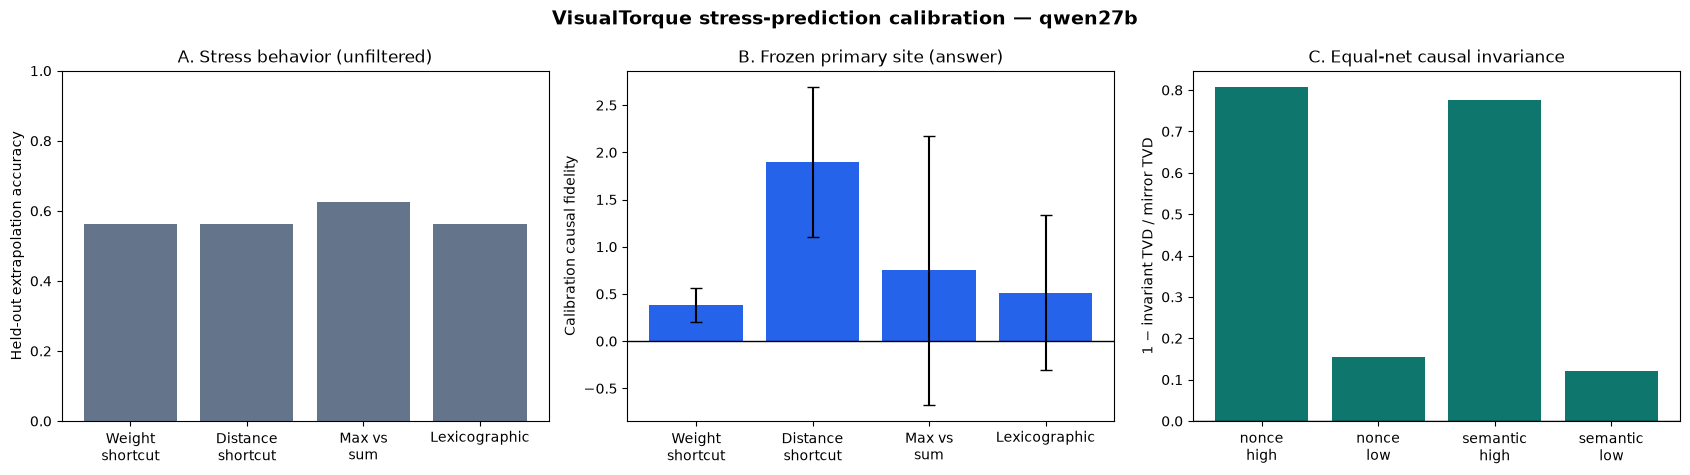

Saved: /content/drive/MyDrive/VisualTorque/results/model_adaptive_fidelity_stress_prediction_v1/models/Qwen__Qwen3.5-27B__373612cb/analysis/figures/model_stress_prediction_diagnostics.png


In [16]:
%%cell_progress 15/17 Save the model-facing stress-prediction diagnostic figure
cell_stage('Rendering behavior, causal fidelity, and invariance panels')
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
cell_order = list(PRIMARY_CELLS)
cell_labels = {
    'weight_conflict': 'Weight\nshortcut',
    'distance_conflict': 'Distance\nshortcut',
    'max_vs_sum': 'Max vs\nsum',
    'lexicographic_conflict': 'Lexicographic',
}

accuracy = prediction_frame.groupby('diagnostic_cell')['base_correct'].mean()
axes[0].bar(
    np.arange(len(cell_order)), [accuracy[cell] for cell in cell_order],
    color='#64748B',
)
axes[0].set_xticks(
    np.arange(len(cell_order)), [cell_labels[cell] for cell in cell_order]
)
axes[0].set_ylim(0, 1)
axes[0].set_ylabel('Held-out extrapolation accuracy')
axes[0].set_title('A. Stress behavior (unfiltered)')

route_plot = primary_states.groupby('diagnostic_cell')[
    'calibration_route_fidelity'
].agg(['mean', 'std']).reindex(cell_order)
axes[1].bar(
    np.arange(len(cell_order)), route_plot['mean'],
    yerr=route_plot['std'], capsize=4, color='#2563EB',
)
axes[1].axhline(0, color='black', linewidth=1)
axes[1].set_xticks(
    np.arange(len(cell_order)), [cell_labels[cell] for cell in cell_order]
)
axes[1].set_ylabel('Calibration causal fidelity')
axes[1].set_title(f'B. Frozen primary site ({PRIMARY_SITE_ROLE})')

equal_primary = equal_summary[
    equal_summary['site_role'] == PRIMARY_SITE_ROLE
].copy()
equal_primary['label'] = (
    equal_primary['prompt_style'] + '\n' + equal_primary['margin_band']
)
axes[2].bar(
    np.arange(len(equal_primary)), equal_primary['causal_invariance_fidelity'],
    color='#0F766E',
)
axes[2].axhline(0, color='black', linewidth=1)
axes[2].set_xticks(
    np.arange(len(equal_primary)), equal_primary['label']
)
axes[2].set_ylabel('1 − invariant TVD / mirror TVD')
axes[2].set_title('C. Equal-net causal invariance')

fig.suptitle(
    f'VisualTorque stress-prediction calibration — {MODEL_KEY}',
    fontsize=14, fontweight='bold',
)
fig.tight_layout()
figure_path = FIGURE_DIR / 'model_stress_prediction_diagnostics.png'
fig.savefig(figure_path, dpi=220, bbox_inches='tight')
plt.show()
print('Saved:', figure_path)


In [17]:
%%cell_progress 16/17 Seal the model run without inspecting cross-model prediction gates
cell_stage('Writing the per-model preregistered handoff')

model_summary = {
    'schema_version': 'fidelity-stress-model-handoff-1.0',
    'model_key': MODEL_KEY,
    'model_id': MODEL_ID,
    'manifest_sha256': manifest_sha256,
    'protocol_sha256': protocol_sha256,
    'primary_site_role': PRIMARY_SITE_ROLE,
    'alternate_site_role': ALTERNATE_SITE_ROLE,
    'calibration_families': EXPECTED_CALIBRATION,
    'outcome_test_families': EXPECTED_TEST,
    'primary_prediction_rows': int(len(prediction_frame)),
    'primary_prediction_states': int(
        prediction_frame['prediction_state_id'].nunique()
    ),
    'control_informative': bool(control_informative),
    'test_prevalence': float(prediction_frame['base_correct'].mean()),
    'test_positives': int(prediction_frame['base_correct'].sum()),
    'status': (
        'model_run_complete_awaiting_cross_model_prediction'
        if control_informative else
        'model_run_complete_primary_site_control_failed_on_stress_support'
    ),
    'nonconditioning_check': (
        'calibration and outcome-test family IDs are disjoint; route states '
        'were frozen before cross-model prediction'
    ),
}
write_json_atomic(OUTPUT_ROOT / 'model_stress_summary.json', model_summary)
display(model_summary)


Seal the model run without inspecting cross-model prediction gates:  88%|########8 | 15/17 [00:00<?, ?cell/s]

{'schema_version': 'fidelity-stress-model-handoff-1.0',
 'model_key': 'qwen27b',
 'model_id': 'Qwen/Qwen3.5-27B',
 'manifest_sha256': 'sha256:ce8f34c8d423fdaf004a0b9b5d8dbbef8a43e636b8445f402cdfcb3e5bc8306a',
 'protocol_sha256': 'sha256:0fcfeb4208a6ace51b7202117fda59b4b8b5a3336fe17fd727fcf6c0f9ec7a26',
 'primary_site_role': 'answer',
 'alternate_site_role': 'options',
 'calibration_families': 96,
 'outcome_test_families': 96,
 'primary_prediction_rows': 64,
 'primary_prediction_states': 16,
 'control_informative': True,
 'test_prevalence': 0.578125,
 'test_positives': 37,
 'status': 'model_run_complete_awaiting_cross_model_prediction',
 'nonconditioning_check': 'calibration and outcome-test family IDs are disjoint; route states were frozen before cross-model prediction'}

Run the optional three-model predictive-validity audit:  94%|#########4| 16/17 [00:00<?, ?cell/s]

Available same-manifest models: ['qwen9b', 'gemma12b', 'qwen27b']


Leave-one-state-out prediction:   0%|          | 0/48 [00:00<?, ?state/s]

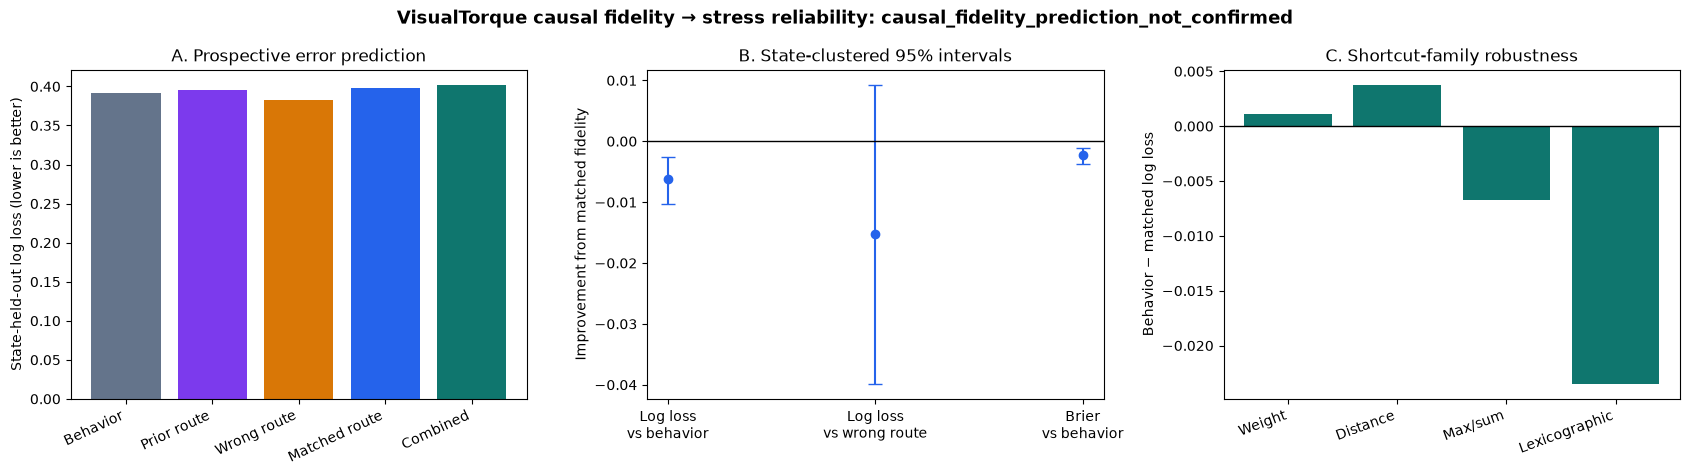

,feature_set,n,log_loss,brier,auroc
0,behavior,192,0.3915,0.1220,0.8708
1,combined_mechanism,192,0.4014,0.1257,0.8629
2,matched_calibration_mechanism,192,0.3976,0.1243,0.8654
3,metadata,192,0.3843,0.1201,0.8688
4,prior_mechanism,192,0.3950,0.1233,0.8681
5,wrong_calibration_mechanism,192,0.3825,0.1176,0.8890


,comparison,states,estimate,ci_low,ci_high,sign_flip_p
0,logloss_behavior_minus_matched,48,-0.0062,-0.0103,-0.0026,0.0010
1,logloss_wrong_minus_matched,48,-0.0152,-0.0399,0.0093,0.2484
2,brier_behavior_minus_matched,48,-0.0023,-0.0037,-0.0010,0.0007
3,logloss_behavior_minus_prior,48,-0.0035,-0.0053,-0.0020,0.0000
4,logloss_behavior_minus_combined,48,-0.0099,-0.0150,-0.0055,0.0000


,diagnostic_cell,states,mean_logloss_improvement
0,distance_conflict,3,0.0038
1,lexicographic_conflict,3,-0.0235
2,max_vs_sum,3,-0.0067
3,weight_conflict,3,0.0011


,model_key,states,mean_logloss_improvement
0,gemma12b,4,-0.0053
1,qwen27b,4,-0.0000
2,qwen9b,4,-0.0137


,held_model,feature_set,n,log_loss,brier
0,qwen9b,behavior,64,0.4181,0.1347
1,qwen9b,matched_calibration_mechanism,64,0.4216,0.1375
2,gemma12b,behavior,64,0.5353,0.1638
3,gemma12b,matched_calibration_mechanism,64,0.5441,0.1654
4,qwen27b,behavior,64,0.3109,0.0893
5,qwen27b,matched_calibration_mechanism,64,0.3143,0.0894


{'schema_version': 'cross-model-fidelity-stress-prediction-decision-1.0',
 'status': 'causal_fidelity_prediction_not_confirmed',
 'prediction_confirmed': False,
 'manifest_sha256': 'sha256:ce8f34c8d423fdaf004a0b9b5d8dbbef8a43e636b8445f402cdfcb3e5bc8306a',
 'protocol_sha256': 'sha256:0fcfeb4208a6ace51b7202117fda59b4b8b5a3336fe17fd727fcf6c0f9ec7a26',
 'models': ['qwen9b', 'gemma12b', 'qwen27b'],
 'rows': 192,
 'states': 48,
 'prevalence': 0.609375,
 'positives': 117,
 'negatives': 75,
 'positive_cells': 2,
 'required_positive_cells': 3,
 'all_positive_controls_informative': True,
 'primary_tests': [{'comparison': 'logloss_behavior_minus_matched',
   'states': 48,
   'estimate': -0.006153028081222957,
   'ci_low': -0.010348591488956097,
   'ci_high': -0.002601853640600263,
   'sign_flip_p': 0.0010499475026248687},
  {'comparison': 'logloss_wrong_minus_matched',
   'states': 48,
   'estimate': -0.01517735725279396,
   'ci_low': -0.039860468877810314,
   'ci_high': 0.009301437618450745,
   

Cross-model report: /content/drive/MyDrive/VisualTorque/results/model_adaptive_fidelity_stress_prediction_v1/cross_model_analysis/PREDICTION_REPORT.md
Model handoff: /content/drive/MyDrive/VisualTorque/results/model_adaptive_fidelity_stress_prediction_v1/models/Qwen__Qwen3.5-27B__373612cb/MODEL_HANDOFF.md
Model diagnostics: /content/drive/MyDrive/VisualTorque/results/model_adaptive_fidelity_stress_prediction_v1/models/Qwen__Qwen3.5-27B__373612cb/analysis/figures/model_stress_prediction_diagnostics.png


In [18]:
%%cell_progress 17/17 Run the optional three-model predictive-validity audit
cell_stage('Writing the model handoff report')

report_lines = [
    '# Model-Adaptive Fidelity Stress-Prediction Handoff', '',
    f'- Model: `{MODEL_ID}` (`{MODEL_KEY}`)',
    f'- Frozen primary site: `{PRIMARY_SITE_ROLE}`',
    f'- Calibration families: {EXPECTED_CALIBRATION}',
    f'- Outcome-test families: {EXPECTED_TEST}',
    f'- Primary prediction rows: {len(prediction_frame)}',
    f'- Positive-control informative: {control_informative}',
    f'- Stress accuracy: {prediction_frame["base_correct"].mean():.3f}', '',
    'This handoff is descriptive until all three unchanged model runs are '
    'available. No cross-model predictor is fit on a partial model set.',
]
(OUTPUT_ROOT / 'MODEL_HANDOFF.md').write_text(
    '\n'.join(report_lines) + '\n', encoding='utf-8'
)

cell_stage('Checking for all three same-manifest model runs')
model_roots = {
    key: SHARED_ROOT / 'models' / specification['model_slug']
    for key, specification in MODEL_SPECS.items()
}
required_names = (
    'extrapolation_prediction_rows.csv', 'calibration_route_states.csv',
    'capture_config.json', 'model_stress_summary.json',
    'stress_control_gate.json',
)
available_models = [
    key for key, root in model_roots.items()
    if all((root / name).is_file() for name in required_names)
]
print('Available same-manifest models:', available_models)

if len(available_models) == len(MODEL_SPECS):
    cell_stage('Validating identities and assembling prediction rows')
    reference_manifest_hash = sha256_file(MANIFEST_PATH)
    reference_protocol_hash = sha256_file(PROTOCOL_LOCK_PATH)
    prediction_parts = []
    summaries = {}
    controls = {}
    for key, root in model_roots.items():
        capture_config = json.loads(
            (root / 'capture_config.json').read_text(encoding='utf-8')
        )['identity']
        assert capture_config['manifest_sha256'] == reference_manifest_hash
        assert capture_config['protocol_sha256'] == reference_protocol_hash
        summary = json.loads(
            (root / 'model_stress_summary.json').read_text(encoding='utf-8')
        )
        assert summary['manifest_sha256'] == reference_manifest_hash
        assert summary['protocol_sha256'] == reference_protocol_hash
        part = pd.read_csv(root / 'extrapolation_prediction_rows.csv')
        assert set(part['model_key']) == {key}
        prediction_parts.append(part)
        summaries[key] = summary
        controls[key] = json.loads(
            (root / 'stress_control_gate.json').read_text(encoding='utf-8')
        )
    all_predictions = pd.concat(prediction_parts, ignore_index=True)
    assert len(all_predictions) == len(MODEL_SPECS) * len(PRIMARY_CELLS) * 16
    assert all_predictions['prediction_state_id'].nunique() == 48
    assert all_predictions.groupby('prediction_state_id').size().eq(4).all()
    assert not all_predictions.isna().any().any()
    all_predictions.to_csv(
        CROSS_MODEL_DIR / 'cross_model_prediction_rows.csv', index=False
    )

    cell_stage('Running fixed leave-one-state-out logistic prediction')
    FEATURE_SETS = (
        'metadata', 'behavior', 'prior_mechanism',
        'wrong_calibration_mechanism', 'matched_calibration_mechanism',
        'combined_mechanism',
    )
    CATEGORICAL_LEVELS = {
        'model_key': tuple(MODEL_SPECS),
        'diagnostic_cell': PRIMARY_CELLS,
        'prompt_style': PROMPT_STYLES,
        'margin_band': MARGIN_BANDS,
        'orientation': ('left', 'right'),
        'structure': ('single', 'multi'),
    }
    BASE_NUMERIC = (
        'normalized_margin', 'log_total_torque', 'stack_count',
    )
    NUMERIC_FEATURES = {
        'metadata': BASE_NUMERIC,
        'behavior': BASE_NUMERIC + (
            'clean_top1_gap', 'clean_normalized_entropy',
            'prior_inrange_accuracy',
        ),
        'prior_mechanism': BASE_NUMERIC + (
            'clean_top1_gap', 'clean_normalized_entropy',
            'prior_inrange_accuracy', 'prior_route_fidelity',
        ),
        'wrong_calibration_mechanism': BASE_NUMERIC + (
            'clean_top1_gap', 'clean_normalized_entropy',
            'prior_inrange_accuracy', 'wrong_calibration_route_fidelity',
        ),
        'matched_calibration_mechanism': BASE_NUMERIC + (
            'clean_top1_gap', 'clean_normalized_entropy',
            'prior_inrange_accuracy', 'calibration_route_fidelity',
        ),
        'combined_mechanism': BASE_NUMERIC + (
            'clean_top1_gap', 'clean_normalized_entropy',
            'prior_inrange_accuracy', 'prior_route_fidelity',
            'calibration_route_fidelity',
        ),
    }

    def categorical_matrix(frame):
        columns = []
        names = []
        for column, levels in CATEGORICAL_LEVELS.items():
            values = frame[column].astype(str).to_numpy()
            assert set(values).issubset(set(levels)), (column, set(values))
            for level in levels[1:]:
                columns.append((values == level).astype(float))
                names.append(f'{column}={level}')
        return np.column_stack(columns), names

    def design_matrices(train, test, feature_set):
        train_cat, cat_names = categorical_matrix(train)
        test_cat, _ = categorical_matrix(test)
        numeric = NUMERIC_FEATURES[feature_set]
        train_num = train[list(numeric)].to_numpy(dtype=float)
        test_num = test[list(numeric)].to_numpy(dtype=float)
        means = train_num.mean(axis=0)
        scales = train_num.std(axis=0)
        scales[scales < 1e-8] = 1.0
        train_num = (train_num - means) / scales
        test_num = (test_num - means) / scales
        train_x = np.column_stack([
            np.ones(len(train)), train_cat, train_num,
        ])
        test_x = np.column_stack([
            np.ones(len(test)), test_cat, test_num,
        ])
        names = ['intercept'] + cat_names + list(numeric)
        return train_x, test_x, names

    def sigmoid(values):
        values = np.clip(values, -30, 30)
        return 1.0 / (1.0 + np.exp(-values))

    def fit_logistic(x, y, l2=1.0, max_iter=100):
        y = np.asarray(y, dtype=float)
        assert set(np.unique(y)).issubset({0.0, 1.0})
        assert 0 < y.mean() < 1
        beta = np.zeros(x.shape[1], dtype=float)
        penalty = np.eye(x.shape[1], dtype=float) * l2
        penalty[0, 0] = 0.0
        for _ in range(max_iter):
            probability = sigmoid(x @ beta)
            weight = np.clip(probability * (1 - probability), 1e-6, None)
            gradient = x.T @ (y - probability) - penalty @ beta
            information = x.T @ (x * weight[:, None]) + penalty
            step = np.linalg.solve(information, gradient)
            beta += step
            if np.max(np.abs(step)) < 1e-8:
                break
        return beta

    oof_rows = []
    for state_id in tqdm(
        sorted(all_predictions['prediction_state_id'].unique()),
        desc='Leave-one-state-out prediction', unit='state',
    ):
        test_mask = all_predictions['prediction_state_id'] == state_id
        train = all_predictions.loc[~test_mask].copy()
        test = all_predictions.loc[test_mask].copy()
        y_train = train['base_correct'].to_numpy(dtype=float)
        assert 0 < y_train.mean() < 1
        for feature_set in FEATURE_SETS:
            train_x, test_x, _ = design_matrices(train, test, feature_set)
            beta = fit_logistic(train_x, y_train)
            probabilities = sigmoid(test_x @ beta)
            for row_index, probability in zip(test.index, probabilities):
                oof_rows.append({
                    'row_index': int(row_index),
                    'prediction_state_id': state_id,
                    'feature_set': feature_set,
                    'probability': float(np.clip(probability, 1e-6, 1 - 1e-6)),
                })
    oof_frame = pd.DataFrame(oof_rows)
    assert len(oof_frame) == len(all_predictions) * len(FEATURE_SETS)
    assert not oof_frame.duplicated(['row_index', 'feature_set']).any()
    outcome_lookup = all_predictions['base_correct'].to_dict()
    oof_frame['target'] = oof_frame['row_index'].map(outcome_lookup).astype(int)
    oof_frame['log_loss'] = -(
        oof_frame['target'] * np.log(oof_frame['probability'])
        + (1 - oof_frame['target']) * np.log(1 - oof_frame['probability'])
    )
    oof_frame['brier'] = (
        oof_frame['probability'] - oof_frame['target']
    ) ** 2
    oof_frame.to_csv(
        CROSS_MODEL_DIR / 'leave_one_state_out_predictions.csv', index=False
    )

    def auc_score(y, score):
        y = np.asarray(y, dtype=int)
        score = np.asarray(score, dtype=float)
        positives = int(y.sum())
        negatives = len(y) - positives
        if positives == 0 or negatives == 0:
            return np.nan
        order = np.argsort(score, kind='mergesort')
        ranks = np.empty(len(score), dtype=float)
        sorted_score = score[order]
        start = 0
        while start < len(score):
            end = start + 1
            while end < len(score) and sorted_score[end] == sorted_score[start]:
                end += 1
            ranks[order[start:end]] = (start + 1 + end) / 2.0
            start = end
        return float(
            (ranks[y == 1].sum() - positives * (positives + 1) / 2)
            / (positives * negatives)
        )

    metric_rows = []
    for feature_set, group in oof_frame.groupby('feature_set'):
        metric_rows.append({
            'feature_set': feature_set,
            'n': int(len(group)),
            'log_loss': float(group['log_loss'].mean()),
            'brier': float(group['brier'].mean()),
            'auroc': auc_score(group['target'], group['probability']),
        })
    metric_frame = pd.DataFrame(metric_rows)
    metric_frame.to_csv(
        CROSS_MODEL_DIR / 'prediction_metrics.csv', index=False
    )

    state_metric = oof_frame.groupby([
        'prediction_state_id', 'feature_set'
    ])[['log_loss', 'brier']].mean().reset_index()
    state_log = state_metric.pivot(
        index='prediction_state_id', columns='feature_set', values='log_loss'
    )
    state_brier = state_metric.pivot(
        index='prediction_state_id', columns='feature_set', values='brier'
    )

    def paired_state_test(values, seed):
        values = np.asarray(values, dtype=float)
        generator = np.random.default_rng(seed)
        indices = generator.integers(
            0, len(values), size=(BOOTSTRAP_REPLICATES, len(values))
        )
        distribution = values[indices].mean(axis=1)
        signs = generator.choice(
            (-1.0, 1.0), size=(SIGN_FLIP_REPLICATES, len(values))
        )
        null = (signs * values[None, :]).mean(axis=1)
        estimate = float(values.mean())
        return {
            'states': int(len(values)),
            'estimate': estimate,
            'ci_low': float(np.quantile(distribution, .025)),
            'ci_high': float(np.quantile(distribution, .975)),
            'sign_flip_p': float(
                (1 + np.sum(np.abs(null) >= abs(estimate)))
                / (SIGN_FLIP_REPLICATES + 1)
            ),
        }

    comparison_specs = (
        ('logloss_behavior_minus_matched',
         state_log['behavior'] - state_log['matched_calibration_mechanism']),
        ('logloss_wrong_minus_matched',
         state_log['wrong_calibration_mechanism']
         - state_log['matched_calibration_mechanism']),
        ('brier_behavior_minus_matched',
         state_brier['behavior'] - state_brier['matched_calibration_mechanism']),
        ('logloss_behavior_minus_prior',
         state_log['behavior'] - state_log['prior_mechanism']),
        ('logloss_behavior_minus_combined',
         state_log['behavior'] - state_log['combined_mechanism']),
    )
    comparison_rows = []
    for index, (name, values) in enumerate(comparison_specs):
        comparison_rows.append({
            'comparison': name,
            **paired_state_test(values.to_numpy(), SEED + 500 + index),
        })
    comparison_frame = pd.DataFrame(comparison_rows)
    comparison_frame.to_csv(
        CROSS_MODEL_DIR / 'state_clustered_prediction_tests.csv', index=False
    )

    row_meta = all_predictions.set_index(
        'prediction_state_id'
    )[['diagnostic_cell', 'model_key']].drop_duplicates()
    improvement = pd.DataFrame({
        'prediction_state_id': state_log.index,
        'behavior_minus_matched_logloss': (
            state_log['behavior'] - state_log['matched_calibration_mechanism']
        ).to_numpy(),
    }).merge(
        row_meta.reset_index(), on='prediction_state_id', validate='one_to_one'
    )
    cell_robustness = improvement.groupby('diagnostic_cell').agg(
        states=('prediction_state_id', 'size'),
        mean_logloss_improvement=('behavior_minus_matched_logloss', 'mean'),
    ).reset_index()
    model_robustness = improvement.groupby('model_key').agg(
        states=('prediction_state_id', 'size'),
        mean_logloss_improvement=('behavior_minus_matched_logloss', 'mean'),
    ).reset_index()
    cell_robustness.to_csv(
        CROSS_MODEL_DIR / 'prediction_cell_robustness.csv', index=False
    )
    model_robustness.to_csv(
        CROSS_MODEL_DIR / 'prediction_model_robustness.csv', index=False
    )

    cell_stage('Running secondary leave-one-model-out transfer')
    transfer_rows = []
    for held_model in MODEL_SPECS:
        train = all_predictions[all_predictions['model_key'] != held_model]
        test = all_predictions[all_predictions['model_key'] == held_model]
        y_train = train['base_correct'].to_numpy(dtype=float)
        for feature_set in ('behavior', 'matched_calibration_mechanism'):
            train_x, test_x, _ = design_matrices(train, test, feature_set)
            beta = fit_logistic(train_x, y_train)
            probability = np.clip(sigmoid(test_x @ beta), 1e-6, 1 - 1e-6)
            y_test = test['base_correct'].to_numpy(dtype=float)
            log_loss = float(np.mean(-(
                y_test * np.log(probability)
                + (1 - y_test) * np.log(1 - probability)
            )))
            transfer_rows.append({
                'held_model': held_model,
                'feature_set': feature_set,
                'n': int(len(test)),
                'log_loss': log_loss,
                'brier': float(np.mean((probability - y_test) ** 2)),
            })
    transfer_frame = pd.DataFrame(transfer_rows)
    transfer_frame.to_csv(
        CROSS_MODEL_DIR / 'leave_one_model_out_transfer.csv', index=False
    )

    prevalence = float(all_predictions['base_correct'].mean())
    positives = int(all_predictions['base_correct'].sum())
    negatives = int(len(all_predictions) - positives)
    comparison_lookup = comparison_frame.set_index('comparison')
    behavior_test = comparison_lookup.loc['logloss_behavior_minus_matched']
    wrong_test = comparison_lookup.loc['logloss_wrong_minus_matched']
    brier_test = comparison_lookup.loc['brier_behavior_minus_matched']
    positive_cells = int(
        (cell_robustness['mean_logloss_improvement'] > 0).sum()
    )
    support_ok = bool(
        MIN_PRIMARY_PREVALENCE <= prevalence <= MAX_PRIMARY_PREVALENCE
        and positives >= MIN_PRIMARY_POSITIVES
        and negatives >= MIN_PRIMARY_POSITIVES
        and all(controls[key]['control_informative'] for key in MODEL_SPECS)
    )
    prediction_confirmed = bool(
        support_ok
        and behavior_test['ci_low'] > 0
        and behavior_test['sign_flip_p'] < PRIMARY_ALPHA
        and wrong_test['ci_low'] > 0
        and wrong_test['sign_flip_p'] < PRIMARY_ALPHA
        and brier_test['ci_low'] > 0
        and positive_cells >= MIN_POSITIVE_CELLS
    )
    if prediction_confirmed:
        status = 'causal_fidelity_predicts_extrapolative_stress_errors'
    elif support_ok and behavior_test['ci_low'] > 0:
        status = 'incremental_prediction_detected_but_full_specificity_gate_failed'
    elif support_ok:
        status = 'causal_fidelity_prediction_not_confirmed'
    else:
        status = 'prediction_support_or_positive_control_gate_failed'

    decision = {
        'schema_version': 'cross-model-fidelity-stress-prediction-decision-1.0',
        'status': status,
        'prediction_confirmed': prediction_confirmed,
        'manifest_sha256': reference_manifest_hash,
        'protocol_sha256': reference_protocol_hash,
        'models': list(MODEL_SPECS),
        'rows': int(len(all_predictions)),
        'states': int(all_predictions['prediction_state_id'].nunique()),
        'prevalence': prevalence,
        'positives': positives,
        'negatives': negatives,
        'positive_cells': positive_cells,
        'required_positive_cells': MIN_POSITIVE_CELLS,
        'all_positive_controls_informative': bool(all(
            controls[key]['control_informative'] for key in MODEL_SPECS
        )),
        'primary_tests': comparison_frame.to_dict(orient='records'),
        'claim_boundary': protocol_identity['interpretation_limit'],
        'probe_control_boundary': (
            'A common probe-decodability covariate is not included because no '
            'same-protocol Qwen-27B probe exists. The formal control is causal '
            'specificity: matched versus mismatched route fidelity, plus prior '
            'accuracy and label-free confidence.'
        ),
    }
    write_json_atomic(
        CROSS_MODEL_DIR / 'fidelity_stress_prediction_decision.json', decision
    )

    cell_stage('Saving paper-facing cross-model prediction figure')
    import matplotlib.pyplot as plt
    figure, axes = plt.subplots(1, 3, figsize=(17, 4.8))
    metric_plot = metric_frame.set_index('feature_set').loc[[
        'behavior', 'prior_mechanism', 'wrong_calibration_mechanism',
        'matched_calibration_mechanism', 'combined_mechanism',
    ]]
    labels = ['Behavior', 'Prior route', 'Wrong route', 'Matched route', 'Combined']
    axes[0].bar(np.arange(len(labels)), metric_plot['log_loss'], color=[
        '#64748B', '#7C3AED', '#D97706', '#2563EB', '#0F766E',
    ])
    axes[0].set_xticks(np.arange(len(labels)), labels, rotation=25, ha='right')
    axes[0].set_ylabel('State-held-out log loss (lower is better)')
    axes[0].set_title('A. Prospective error prediction')

    comparison_plot = comparison_frame.iloc[:3]
    axes[1].errorbar(
        np.arange(len(comparison_plot)), comparison_plot['estimate'],
        yerr=np.vstack([
            comparison_plot['estimate'] - comparison_plot['ci_low'],
            comparison_plot['ci_high'] - comparison_plot['estimate'],
        ]), fmt='o', capsize=5, color='#2563EB',
    )
    axes[1].axhline(0, color='black', linewidth=1)
    axes[1].set_xticks(np.arange(3), [
        'Log loss\nvs behavior', 'Log loss\nvs wrong route',
        'Brier\nvs behavior',
    ])
    axes[1].set_ylabel('Improvement from matched fidelity')
    axes[1].set_title('B. State-clustered 95% intervals')

    cell_plot = cell_robustness.set_index('diagnostic_cell').reindex(PRIMARY_CELLS)
    axes[2].bar(
        np.arange(len(PRIMARY_CELLS)), cell_plot['mean_logloss_improvement'],
        color='#0F766E',
    )
    axes[2].axhline(0, color='black', linewidth=1)
    axes[2].set_xticks(np.arange(len(PRIMARY_CELLS)), [
        'Weight', 'Distance', 'Max/sum', 'Lexicographic',
    ], rotation=20, ha='right')
    axes[2].set_ylabel('Behavior − matched log loss')
    axes[2].set_title('C. Shortcut-family robustness')
    figure.suptitle(
        f'VisualTorque causal fidelity → stress reliability: {status}',
        fontsize=13, fontweight='bold',
    )
    figure.tight_layout()
    cross_figure_path = CROSS_MODEL_DIR / 'fidelity_stress_prediction.png'
    figure.savefig(cross_figure_path, dpi=220, bbox_inches='tight')
    plt.show()

    report = [
        '# Cross-Model Causal-Fidelity Stress Prediction', '',
        f'- Decision: **{status}**',
        f'- Rows / held-out states: {len(all_predictions)} / '
        f'{all_predictions["prediction_state_id"].nunique()}',
        f'- Accuracy prevalence: {prevalence:.3f}',
        f'- Positive shortcut cells: {positive_cells} / {len(PRIMARY_CELLS)}',
        '', '## Primary comparisons', '',
    ]
    for row in comparison_frame.to_dict(orient='records'):
        report.append(
            f'- `{row["comparison"]}`: {row["estimate"]:.4f} '
            f'[{row["ci_low"]:.4f}, {row["ci_high"]:.4f}], '
            f'p={row["sign_flip_p"]:.4g}.'
        )
    report.extend([
        '', '## Interpretation boundary', '',
        decision['claim_boundary'], '',
        decision['probe_control_boundary'],
    ])
    (CROSS_MODEL_DIR / 'PREDICTION_REPORT.md').write_text(
        '\n'.join(report) + '\n', encoding='utf-8'
    )
    display(metric_frame.round(4))
    display(comparison_frame.round(4))
    display(cell_robustness.round(4))
    display(model_robustness.round(4))
    display(transfer_frame.round(4))
    display(decision)
    print('Cross-model report:', CROSS_MODEL_DIR / 'PREDICTION_REPORT.md')
else:
    print(
        'Cross-model prediction deferred. Run this unchanged notebook with '
        "MODEL_KEY='qwen9b', 'gemma12b', and 'qwen27b'."
    )

print('Model handoff:', OUTPUT_ROOT / 'MODEL_HANDOFF.md')
print('Model diagnostics:', FIGURE_DIR / 'model_stress_prediction_diagnostics.png')
